# Пересчёт таблиц и рисунков

Ноутбук выполняет анализ сохранённых измерений. Обучение и Betti matching не запускаются. Все данные из `data/observations.json` и `data/window_timings.csv` встроены в ноутбук.

In [ ]:
from pathlib import Path
from io import StringIO
import json, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Все исходные данные встроены: сеть и локальные модули не нужны
SAVE_OUTPUTS = False
OUTPUT = Path('output')
obs = json.loads('{"schema_version": 1, "measurement_date": "2026-10-19", "shape": [125, 256, 128], "repetitions": 5, "environment": {"os": "Windows-10-10.0.19045-SP0", "python": "3.13.5", "cpu": "Intel(R) Core(TM) i5-10400F CPU @ 2.90GHz", "cores_physical": 6, "cores_logical": 12, "ram_gb": 15.9, "numpy": "2.1.3"}, "implementation": {"repository": "https://github.com/nstucki/Betti-Matching-3D", "commit": "db623be7456ae451beb422af3bbcea94e9863a8f", "compiler": "MSVC 19.44", "preprocessor_token_patch": true, "historical_binary_sha256": null}, "calibration": {"checkpoint": 4000, "split": "val", "full_wall_median_s": 17.975970099999927, "full_cpu_median_s": 25.890625, "alpha_wall_saved": 1.0796427649578302, "configurations": [{"core_side": 16, "margin": 4, "window_count": 1024, "windows_wall_sum_medians_s": 36.62459559999894, "windows_cpu_sum_medians_s": 45.4375}, {"core_side": 16, "margin": 8, "window_count": 1024, "windows_wall_sum_medians_s": 87.65863990000383, "windows_cpu_sum_medians_s": 113.1875}, {"core_side": 32, "margin": 4, "window_count": 128, "windows_wall_sum_medians_s": 23.029303199999788, "windows_cpu_sum_medians_s": 30.46875}, {"core_side": 32, "margin": 8, "window_count": 128, "windows_wall_sum_medians_s": 37.115490900000566, "windows_cpu_sum_medians_s": 49.71875}, {"core_side": 64, "margin": 4, "window_count": 16, "windows_wall_sum_medians_s": 17.9336275, "windows_cpu_sum_medians_s": 25.0625}, {"core_side": 64, "margin": 8, "window_count": 16, "windows_wall_sum_medians_s": 22.012207200000034, "windows_cpu_sum_medians_s": 30.8125}]}, "test": {"core_side": 32, "margin": 4, "checkpoints": {"500": {"full_wall_passes_s": [18.488609300000007, 18.212699300000054, 18.385943399999974, 18.222297000000026, 18.23361669999997], "windows_wall_passes_s": [24.236716899999976, 23.531616299999996, 23.66691549999996, 23.46242319999999, 23.560649300000023], "full_wall_median_s": 18.23361669999997, "windows_wall_median_s": 23.560649300000023, "all_window_discrepancy": {"L_ratio": 0.856213385490986, "cos": 0.7705341121217238, "rel_l2": 0.6649274910940979}}, "1500": {"full_wall_passes_s": [17.846987900000045, 17.91065679999997, 21.354991400000017, 17.88206459999992, 18.018174099999896], "windows_wall_passes_s": [22.75427389999993, 22.738005899999962, 23.59734790000016, 22.64575859999991, 22.637336700000105], "full_wall_median_s": 17.91065679999997, "windows_wall_median_s": 22.738005899999962, "all_window_discrepancy": {"L_ratio": 0.8151061551210053, "cos": 0.7137864418658545, "rel_l2": 0.7402526111103603}}, "4000": {"full_wall_passes_s": [17.715256699999827, 17.716580900000054, 17.71858169999996, 17.804918999999927, 17.894104799999923], "windows_wall_passes_s": [22.38918919999992, 22.293639600000006, 22.408472000000074, 22.397209900000007, 22.398013099999844], "full_wall_median_s": 17.71858169999996, "windows_wall_median_s": 22.397209900000007, "all_window_discrepancy": {"L_ratio": 0.7267784591973341, "cos": 0.7271964330172237, "rel_l2": 0.6982754141561344}}}}, "test_larger_windows": {"checkpoint": 4000, "core_side": 64, "margin": 4, "windows_wall_passes_s": [17.77882199999999, 17.756359699999848, 18.759638900000027, 17.787252900000112, 17.852844100000084], "windows_wall_median_s": 17.787252900000112}, "parallel": {"checkpoint": 4000, "core_side": 32, "margin": 4, "chunk": 12, "full_wall_median_s": 17.760958200000005, "windows_wall_median_s": 5.828091500000028}}')
window_timings = pd.read_csv(StringIO('z0,z1,y0,y1,x0,x1,voxels,t_median_s,t_cpu_median_s\n0,20,0,20,0,20,8000,0.017184,0.015625\n0,20,0,20,12,36,9600,0.018541,0.015625\n0,20,0,20,28,52,9600,0.023928,0.031250\n0,20,0,20,44,68,9600,0.053999,0.046875\n0,20,0,20,60,84,9600,0.029546,0.031250\n0,20,0,20,76,100,9600,0.018827,0.015625\n0,20,0,20,92,116,9600,0.019010,0.031250\n0,20,0,20,108,128,8000,0.016128,0.031250\n0,20,12,36,0,20,9600,0.022699,0.015625\n0,20,12,36,12,36,11520,0.025166,0.031250\n0,20,12,36,28,52,11520,0.031520,0.046875\n0,20,12,36,44,68,11520,0.044629,0.046875\n0,20,12,36,60,84,11520,0.030510,0.031250\n0,20,12,36,76,100,11520,0.035253,0.031250\n0,20,12,36,92,116,11520,0.025778,0.031250\n0,20,12,36,108,128,9600,0.025946,0.031250\n0,20,28,52,0,20,9600,0.021744,0.031250\n0,20,28,52,12,36,11520,0.031715,0.031250\n0,20,28,52,28,52,11520,0.025870,0.031250\n0,20,28,52,44,68,11520,0.024491,0.031250\n0,20,28,52,60,84,11520,0.039630,0.031250\n0,20,28,52,76,100,11520,0.054851,0.046875\n0,20,28,52,92,116,11520,0.025652,0.031250\n0,20,28,52,108,128,9600,0.032705,0.062500\n0,20,28,68,12,36,19200,0.053031,0.062500\n0,20,44,68,0,20,9600,0.021275,0.015625\n0,20,44,68,12,36,11520,0.028488,0.046875\n0,20,44,68,28,52,11520,0.035377,0.031250\n0,20,44,68,44,68,11520,0.025479,0.031250\n0,20,44,68,60,84,11520,0.043528,0.046875\n0,20,44,68,76,100,11520,0.045806,0.046875\n0,20,44,68,92,116,11520,0.029442,0.046875\n0,20,44,68,108,128,9600,0.037379,0.046875\n0,20,60,84,0,20,9600,0.019462,0.031250\n0,20,60,84,12,36,11520,0.025617,0.015625\n0,20,60,84,28,52,11520,0.051547,0.062500\n0,20,60,84,44,68,11520,0.045925,0.046875\n0,20,60,84,60,84,11520,0.026521,0.031250\n0,20,60,84,76,100,11520,0.027130,0.031250\n0,20,60,84,92,116,11520,0.030386,0.046875\n0,20,60,84,108,128,9600,0.037065,0.062500\n0,20,76,100,0,20,9600,0.018778,0.031250\n0,20,76,100,12,36,11520,0.031390,0.031250\n0,20,76,100,28,52,11520,0.040684,0.046875\n0,20,76,100,44,68,11520,0.043885,0.046875\n0,20,76,100,60,84,11520,0.026607,0.031250\n0,20,76,100,76,100,11520,0.030617,0.031250\n0,20,76,100,92,116,11520,0.027337,0.031250\n0,20,76,100,108,128,9600,0.023327,0.031250\n0,20,92,116,0,20,9600,0.019288,0.031250\n0,20,92,116,12,36,11520,0.029175,0.031250\n0,20,92,116,28,52,11520,0.061736,0.062500\n0,20,92,116,44,68,11520,0.035302,0.031250\n0,20,92,116,60,84,11520,0.028755,0.046875\n0,20,92,116,76,100,11520,0.025649,0.031250\n0,20,92,116,92,116,11520,0.022617,0.031250\n0,20,92,116,108,128,9600,0.019496,0.015625\n0,20,108,132,0,20,9600,0.021344,0.015625\n0,20,108,132,12,36,11520,0.024453,0.046875\n0,20,108,132,28,52,11520,0.028941,0.031250\n0,20,108,132,44,68,11520,0.037848,0.062500\n0,20,108,132,60,84,11520,0.033953,0.031250\n0,20,108,132,76,100,11520,0.039191,0.031250\n0,20,108,132,92,116,11520,0.028182,0.046875\n0,20,108,132,108,128,9600,0.019599,0.015625\n0,20,124,148,0,20,9600,0.019475,0.015625\n0,20,124,148,12,36,11520,0.024467,0.015625\n0,20,124,148,28,52,11520,0.032261,0.046875\n0,20,124,148,44,68,11520,0.040678,0.062500\n0,20,124,148,60,84,11520,0.041753,0.031250\n0,20,124,148,76,100,11520,0.056193,0.062500\n0,20,124,148,92,116,11520,0.059442,0.062500\n0,20,124,148,108,128,9600,0.022071,0.031250\n0,20,140,164,0,20,9600,0.024442,0.031250\n0,20,140,164,12,36,11520,0.026971,0.046875\n0,20,140,164,28,52,11520,0.023752,0.031250\n0,20,140,164,44,68,11520,0.025731,0.031250\n0,20,140,164,60,84,11520,0.051586,0.078125\n0,20,140,164,76,100,11520,0.051522,0.046875\n0,20,140,164,92,116,11520,0.053005,0.046875\n0,20,140,164,108,128,9600,0.020804,0.031250\n0,20,156,180,0,20,9600,0.028392,0.031250\n0,20,156,180,12,36,11520,0.030873,0.046875\n0,20,156,180,28,52,11520,0.027239,0.046875\n0,20,156,180,44,68,11520,0.032190,0.046875\n0,20,156,180,60,84,11520,0.034593,0.031250\n0,20,156,180,76,100,11520,0.047209,0.062500\n0,20,156,180,92,116,11520,0.046263,0.046875\n0,20,156,180,108,128,9600,0.021397,0.046875\n0,20,172,196,0,20,9600,0.026836,0.031250\n0,20,172,196,12,36,11520,0.036506,0.046875\n0,20,172,196,28,52,11520,0.038652,0.062500\n0,20,172,196,44,68,11520,0.051268,0.046875\n0,20,172,196,60,84,11520,0.038478,0.031250\n0,20,172,196,76,100,11520,0.037701,0.046875\n0,20,172,196,92,116,11520,0.029286,0.031250\n0,20,172,196,108,128,9600,0.021184,0.031250\n0,20,188,212,0,20,9600,0.021510,0.015625\n0,20,188,212,12,36,11520,0.045963,0.046875\n0,20,188,212,28,52,11520,0.043739,0.046875\n0,20,188,212,44,68,11520,0.046603,0.046875\n0,20,188,212,60,84,11520,0.038736,0.046875\n0,20,188,212,76,100,11520,0.054659,0.078125\n0,20,188,212,92,116,11520,0.049212,0.046875\n0,20,188,212,108,128,9600,0.020583,0.031250\n0,20,204,228,0,20,9600,0.020327,0.031250\n0,20,204,228,12,36,11520,0.042757,0.046875\n0,20,204,228,28,52,11520,0.044379,0.046875\n0,20,204,228,44,68,11520,0.026135,0.031250\n0,20,204,228,60,84,11520,0.023595,0.046875\n0,20,204,228,76,100,11520,0.044970,0.046875\n0,20,204,228,92,116,11520,0.046527,0.046875\n0,20,204,228,108,128,9600,0.019827,0.031250\n0,20,220,244,0,20,9600,0.020778,0.031250\n0,20,220,244,12,36,11520,0.024871,0.015625\n0,20,220,244,28,52,11520,0.030622,0.046875\n0,20,220,244,44,68,11520,0.026062,0.031250\n0,20,220,244,60,84,11520,0.024240,0.046875\n0,20,220,244,76,100,11520,0.026868,0.046875\n0,20,220,244,92,116,11520,0.027787,0.031250\n0,20,220,244,108,128,9600,0.020743,0.031250\n0,20,236,256,0,20,8000,0.017746,0.031250\n0,20,236,256,12,36,9600,0.022376,0.031250\n0,20,236,256,28,52,9600,0.024625,0.031250\n0,20,236,256,44,68,9600,0.021347,0.031250\n0,20,236,256,60,84,9600,0.019628,0.015625\n0,20,236,256,76,100,9600,0.025267,0.031250\n0,20,236,256,92,116,9600,0.039391,0.031250\n0,20,236,256,108,128,8000,0.024893,0.031250\n0,24,0,24,0,24,13824,0.032506,0.046875\n0,24,0,24,0,40,23040,0.050009,0.062500\n0,24,0,24,8,40,18432,0.038422,0.046875\n0,24,0,24,24,56,18432,0.053579,0.062500\n0,24,0,24,40,72,18432,0.090399,0.109375\n0,24,0,24,56,88,18432,0.071937,0.093750\n0,24,0,24,72,104,18432,0.041217,0.062500\n0,24,0,24,88,120,18432,0.043261,0.046875\n0,24,0,24,104,128,13824,0.032805,0.031250\n0,24,8,40,0,24,18432,0.044124,0.062500\n0,24,8,40,8,40,24576,0.056924,0.078125\n0,24,8,40,24,56,24576,0.075051,0.093750\n0,24,8,40,40,72,24576,0.095857,0.109375\n0,24,8,40,56,88,24576,0.084957,0.109375\n0,24,8,40,72,104,24576,0.072851,0.109375\n0,24,8,40,88,120,24576,0.070469,0.093750\n0,24,8,40,104,128,18432,0.053943,0.062500\n0,24,24,56,0,24,18432,0.044032,0.062500\n0,24,24,56,8,40,24576,0.065514,0.078125\n0,24,24,56,24,56,24576,0.066863,0.109375\n0,24,24,56,40,72,24576,0.062626,0.078125\n0,24,24,56,56,88,24576,0.091749,0.109375\n0,24,24,56,72,104,24576,0.099694,0.109375\n0,24,24,56,88,120,24576,0.080605,0.093750\n0,24,24,56,104,128,18432,0.069386,0.093750\n0,24,24,72,40,72,36864,0.108408,0.125000\n0,24,40,72,0,24,18432,0.043120,0.046875\n0,24,40,72,8,40,24576,0.064699,0.093750\n0,24,40,72,24,56,24576,0.078297,0.093750\n0,24,40,72,40,72,24576,0.068967,0.109375\n0,24,40,72,56,88,24576,0.085483,0.093750\n0,24,40,72,72,104,24576,0.086777,0.109375\n0,24,40,72,88,120,24576,0.082274,0.109375\n0,24,40,72,104,128,18432,0.075619,0.078125\n0,24,56,88,0,24,18432,0.040470,0.046875\n0,24,56,88,8,40,24576,0.061141,0.078125\n0,24,56,88,24,56,24576,0.113594,0.140625\n0,24,56,88,40,72,24576,0.110751,0.125000\n0,24,56,88,56,88,24576,0.068449,0.093750\n0,24,56,88,72,104,24576,0.065959,0.078125\n0,24,56,88,88,120,24576,0.081619,0.093750\n0,24,56,88,104,128,18432,0.073296,0.093750\n0,24,72,104,0,24,18432,0.039466,0.046875\n0,24,72,104,8,40,24576,0.069737,0.093750\n0,24,72,104,24,56,24576,0.101522,0.140625\n0,24,72,104,40,72,24576,0.093169,0.109375\n0,24,72,104,56,88,24576,0.066891,0.093750\n0,24,72,104,72,104,24576,0.064504,0.078125\n0,24,72,104,88,120,24576,0.064152,0.078125\n0,24,72,104,104,128,18432,0.050906,0.062500\n0,24,88,120,0,24,18432,0.041369,0.062500\n0,24,88,120,8,40,24576,0.070141,0.078125\n0,24,88,120,24,56,24576,0.105299,0.125000\n0,24,88,120,40,72,24576,0.090457,0.109375\n0,24,88,120,56,88,24576,0.067827,0.093750\n0,24,88,120,72,104,24576,0.061334,0.078125\n0,24,88,120,88,120,24576,0.051999,0.062500\n0,24,88,120,104,128,18432,0.039599,0.046875\n0,24,88,136,56,104,55296,0.169731,0.218750\n0,24,104,136,0,24,18432,0.044287,0.062500\n0,24,104,136,8,40,24576,0.060185,0.078125\n0,24,104,136,24,56,24576,0.078367,0.109375\n0,24,104,136,40,72,24576,0.095899,0.125000\n0,24,104,136,56,88,24576,0.088770,0.109375\n0,24,104,136,72,104,24576,0.083870,0.109375\n0,24,104,136,88,120,24576,0.063240,0.078125\n0,24,104,136,104,128,18432,0.041000,0.046875\n0,24,120,152,0,24,18432,0.045422,0.046875\n0,24,120,152,8,40,24576,0.066129,0.078125\n0,24,120,152,24,56,24576,0.071041,0.109375\n0,24,120,152,40,72,24576,0.084655,0.109375\n0,24,120,152,56,88,24576,0.106048,0.140625\n0,24,120,152,72,104,24576,0.142922,0.156250\n0,24,120,152,88,120,24576,0.120349,0.140625\n0,24,120,152,104,128,18432,0.051858,0.062500\n0,24,136,168,0,24,18432,0.052103,0.062500\n0,24,136,168,8,40,24576,0.064869,0.078125\n0,24,136,168,24,56,24576,0.061578,0.078125\n0,24,136,168,40,72,24576,0.070972,0.109375\n0,24,136,168,56,88,24576,0.102746,0.140625\n0,24,136,168,72,104,24576,0.149349,0.171875\n0,24,136,168,88,120,24576,0.142892,0.156250\n0,24,136,168,104,128,18432,0.049086,0.062500\n0,24,152,184,0,24,18432,0.058429,0.078125\n0,24,152,184,8,40,24576,0.073346,0.109375\n0,24,152,184,24,56,24576,0.061324,0.078125\n0,24,152,184,40,72,24576,0.073105,0.093750\n0,24,152,184,56,88,24576,0.080886,0.125000\n0,24,152,184,72,104,24576,0.107191,0.125000\n0,24,152,184,88,120,24576,0.106093,0.125000\n0,24,152,184,104,128,18432,0.046013,0.062500\n0,24,168,200,0,24,18432,0.050755,0.078125\n0,24,168,200,8,40,24576,0.083904,0.109375\n0,24,168,200,24,56,24576,0.082608,0.109375\n0,24,168,200,40,72,24576,0.094320,0.109375\n0,24,168,200,56,88,24576,0.096922,0.125000\n0,24,168,200,72,104,24576,0.085509,0.109375\n0,24,168,200,88,120,24576,0.073215,0.125000\n0,24,168,200,104,128,18432,0.047387,0.062500\n0,24,184,216,0,24,18432,0.044138,0.062500\n0,24,184,216,8,40,24576,0.098038,0.125000\n0,24,184,216,24,56,24576,0.100848,0.125000\n0,24,184,216,40,72,24576,0.088639,0.109375\n0,24,184,216,56,88,24576,0.092921,0.109375\n0,24,184,216,72,104,24576,0.111362,0.156250\n0,24,184,216,88,120,24576,0.101915,0.109375\n0,24,184,216,104,128,18432,0.044819,0.062500\n0,24,200,232,0,24,18432,0.043101,0.078125\n0,24,200,232,8,40,24576,0.084561,0.093750\n0,24,200,232,24,56,24576,0.092868,0.093750\n0,24,200,232,40,72,24576,0.064189,0.078125\n0,24,200,232,56,88,24576,0.058784,0.062500\n0,24,200,232,72,104,24576,0.096125,0.109375\n0,24,200,232,88,120,24576,0.100101,0.109375\n0,24,200,232,104,128,18432,0.044875,0.062500\n0,24,216,248,0,24,18432,0.046516,0.062500\n0,24,216,248,8,40,24576,0.059265,0.078125\n0,24,216,248,24,56,24576,0.067108,0.078125\n0,24,216,248,40,72,24576,0.060186,0.078125\n0,24,216,248,56,88,24576,0.054565,0.062500\n0,24,216,248,72,104,24576,0.064341,0.078125\n0,24,216,248,88,120,24576,0.068655,0.109375\n0,24,216,248,104,128,18432,0.044176,0.062500\n0,24,232,256,0,24,13824,0.035170,0.046875\n0,24,232,256,8,40,18432,0.046436,0.062500\n0,24,232,256,24,56,18432,0.045753,0.062500\n0,24,232,256,40,72,18432,0.043402,0.062500\n0,24,232,256,56,88,18432,0.041647,0.046875\n0,24,232,256,72,104,18432,0.049488,0.062500\n0,24,232,256,88,120,18432,0.060344,0.062500\n0,24,232,256,104,128,13824,0.041816,0.062500\n0,36,0,20,76,100,17280,0.039625,0.046875\n0,36,0,36,0,36,46656,0.109319,0.156250\n0,36,0,36,28,68,51840,0.232554,0.265625\n0,36,0,36,60,100,51840,0.179451,0.218750\n0,36,0,36,92,128,46656,0.165844,0.203125\n0,36,12,36,44,68,20736,0.095874,0.125000\n0,36,12,36,92,128,31104,0.104451,0.109375\n0,36,28,52,60,84,20736,0.062274,0.078125\n0,36,28,68,0,36,51840,0.130274,0.171875\n0,36,28,68,12,36,34560,0.087142,0.093750\n0,36,28,68,28,68,57600,0.171443,0.203125\n0,36,28,68,60,100,57600,0.195204,0.218750\n0,36,28,68,92,116,34560,0.116029,0.156250\n0,36,28,68,92,128,51840,0.211286,0.265625\n0,36,60,84,0,36,31104,0.072259,0.093750\n0,36,60,84,28,68,34560,0.158113,0.171875\n0,36,60,100,0,36,51840,0.126688,0.187500\n0,36,60,100,28,68,57600,0.251902,0.281250\n0,36,60,100,60,100,57600,0.161332,0.203125\n0,36,60,100,92,116,34560,0.097060,0.125000\n0,36,60,100,92,128,51840,0.170922,0.203125\n0,36,92,116,28,68,34560,0.140764,0.171875\n0,36,92,116,108,128,17280,0.039037,0.046875\n0,36,92,132,0,36,51840,0.127272,0.171875\n0,36,92,132,12,36,34560,0.082662,0.093750\n0,36,92,132,28,68,57600,0.224356,0.312500\n0,36,92,132,60,100,57600,0.172398,0.234375\n0,36,92,132,92,128,51840,0.125195,0.187500\n0,36,108,132,12,36,20736,0.047985,0.062500\n0,36,124,164,0,36,51840,0.149191,0.203125\n0,36,124,164,28,68,57600,0.208096,0.281250\n0,36,124,164,60,100,57600,0.301463,0.390625\n0,36,124,164,92,128,51840,0.225275,0.265625\n0,36,156,196,0,36,51840,0.208327,0.312500\n0,36,156,196,28,68,57600,0.197775,0.296875\n0,36,156,196,60,100,57600,0.234288,0.312500\n0,36,156,196,92,128,51840,0.163092,0.218750\n0,36,188,212,44,68,20736,0.066263,0.062500\n0,36,188,228,0,36,51840,0.172510,0.218750\n0,36,188,228,0,68,97920,0.341279,0.406250\n0,36,188,228,28,68,57600,0.223525,0.265625\n0,36,188,228,60,100,57600,0.257728,0.312500\n0,36,188,228,92,128,51840,0.219624,0.281250\n0,36,188,228,108,128,28800,0.074493,0.109375\n0,36,220,256,0,36,46656,0.132183,0.171875\n0,36,220,256,28,68,51840,0.135436,0.187500\n0,36,220,256,60,100,51840,0.133503,0.171875\n0,36,220,256,92,128,46656,0.130955,0.171875\n0,36,236,256,12,36,17280,0.045877,0.062500\n0,40,0,24,0,40,38400,0.090083,0.125000\n0,40,0,40,0,40,64000,0.164806,0.218750\n0,40,0,40,24,72,76800,0.317758,0.375000\n0,40,0,40,40,72,51200,0.257818,0.312500\n0,40,0,40,56,104,76800,0.280665,0.343750\n0,40,0,40,88,128,64000,0.232281,0.265625\n0,40,8,40,40,72,40960,0.179768,0.218750\n0,40,8,40,56,104,61440,0.205798,0.250000\n0,40,24,56,88,120,40960,0.156342,0.187500\n0,40,24,56,88,128,51200,0.200935,0.250000\n0,40,24,72,0,40,76800,0.198966,0.265625\n0,40,24,72,8,40,61440,0.159631,0.203125\n0,40,24,72,24,72,92160,0.297306,0.390625\n0,40,24,72,40,72,61440,0.209603,0.265625\n0,40,24,72,56,104,92160,0.297053,0.375000\n0,40,24,72,88,128,76800,0.313137,0.390625\n0,40,40,72,8,40,40960,0.108481,0.140625\n0,40,56,104,0,40,76800,0.202782,0.265625\n0,40,56,104,24,72,92160,0.368282,0.453125\n0,40,56,104,56,104,92160,0.272712,0.375000\n0,40,56,104,88,128,76800,0.262145,0.328125\n0,40,72,104,0,40,51200,0.134867,0.187500\n0,40,72,104,8,40,40960,0.108555,0.140625\n0,40,88,136,0,40,76800,0.204480,0.296875\n0,40,88,136,24,56,61440,0.221586,0.296875\n0,40,88,136,24,72,92160,0.345269,0.453125\n0,40,88,136,56,104,92160,0.294682,0.406250\n0,40,88,136,88,128,76800,0.193175,0.265625\n0,40,120,168,0,40,76800,0.228509,0.343750\n0,40,120,168,24,72,92160,0.338530,0.484375\n0,40,120,168,56,88,61440,0.312620,0.406250\n0,40,120,168,56,104,92160,0.505434,0.625000\n0,40,120,168,88,120,61440,0.275353,0.328125\n0,40,120,168,88,128,76800,0.314044,0.375000\n0,40,152,200,0,40,76800,0.308572,0.437500\n0,40,152,200,24,72,92160,0.330593,0.421875\n0,40,152,200,56,104,92160,0.423103,0.531250\n0,40,152,200,88,128,76800,0.261253,0.343750\n0,40,184,216,72,104,40960,0.240612,0.296875\n0,40,184,232,0,24,46080,0.119446,0.171875\n0,40,184,232,0,40,76800,0.267593,0.343750\n0,40,184,232,24,72,92160,0.340106,0.421875\n0,40,184,232,56,104,92160,0.410411,0.484375\n0,40,184,232,88,128,76800,0.329322,0.406250\n0,40,216,256,0,40,64000,0.185470,0.250000\n0,40,216,256,24,56,51200,0.150486,0.218750\n0,40,216,256,24,72,76800,0.214623,0.281250\n0,40,216,256,56,104,76800,0.202080,0.265625\n0,40,216,256,88,128,64000,0.182295,0.250000\n0,40,216,256,104,128,38400,0.103428,0.140625\n0,40,232,256,8,40,30720,0.084761,0.093750\n0,52,28,68,12,68,116480,0.334553,0.437500\n0,52,60,116,0,68,198016,0.654640,0.859375\n0,52,124,196,28,68,149760,0.527509,0.750000\n0,52,188,228,0,68,141440,0.461314,0.609375\n0,52,188,256,0,68,240448,0.735760,1.062500\n0,56,8,72,0,72,258048,0.842054,1.125000\n0,68,0,68,0,68,314432,1.031585,1.453125\n0,68,0,68,60,100,184960,0.752303,0.937500\n0,68,0,68,60,116,258944,1.065980,1.343750\n0,68,0,68,60,128,314432,1.309439,1.656250\n0,68,60,116,60,128,258944,0.879746,1.171875\n0,68,60,132,0,68,332928,1.083399,1.515625\n0,68,60,132,60,128,332928,1.134141,1.546875\n0,68,124,196,0,68,332928,1.200884,1.750000\n0,68,124,196,28,68,195840,0.655554,0.921875\n0,68,124,196,60,128,332928,1.409488,1.937500\n0,68,188,228,0,68,184960,0.566056,0.781250\n0,68,188,228,28,68,108800,0.353444,0.468750\n0,68,188,256,0,68,314432,1.036023,1.437500\n0,68,188,256,60,128,314432,1.055386,1.531250\n0,68,220,256,60,128,166464,0.510032,0.703125\n0,72,0,72,0,72,373248,1.287216,1.765625\n0,72,0,72,56,128,373248,1.545128,1.937500\n0,72,8,72,56,120,294912,1.259020,1.593750\n0,72,8,72,56,128,331776,1.337457,1.718750\n0,72,56,104,56,104,165888,0.597753,0.765625\n0,72,56,136,0,72,414720,1.379920,1.984375\n0,72,56,136,56,104,276480,0.958073,1.281250\n0,72,56,136,56,128,414720,1.472794,2.031250\n0,72,120,200,0,72,414720,1.496390,2.187500\n0,72,120,200,8,72,368640,1.337257,1.984375\n0,72,120,200,24,72,276480,0.971193,1.406250\n0,72,120,200,56,120,368640,1.639335,2.156250\n0,72,120,200,56,128,414720,1.764563,2.437500\n0,72,184,232,0,72,248832,0.775554,1.125000\n0,72,184,256,0,72,373248,1.205485,1.687500\n0,72,184,256,56,104,248832,0.881335,1.234375\n0,72,184,256,56,128,373248,1.281596,1.859375\n0,125,0,256,0,128,4096000,17.975970,25.890625\n8,40,0,24,0,24,18432,0.042202,0.046875\n8,40,0,24,8,40,24576,0.055331,0.078125\n8,40,0,24,24,56,24576,0.101160,0.125000\n8,40,0,24,40,72,24576,0.133348,0.156250\n8,40,0,24,56,88,24576,0.105544,0.125000\n8,40,0,24,72,104,24576,0.068387,0.078125\n8,40,0,24,88,120,24576,0.091325,0.109375\n8,40,0,24,104,128,18432,0.075812,0.093750\n8,40,8,40,0,24,24576,0.062461,0.078125\n8,40,8,40,8,40,32768,0.077779,0.093750\n8,40,8,40,24,56,32768,0.110713,0.140625\n8,40,8,40,40,72,32768,0.138244,0.156250\n8,40,8,40,56,88,32768,0.117367,0.140625\n8,40,8,40,72,104,32768,0.083989,0.109375\n8,40,8,40,88,120,32768,0.132960,0.156250\n8,40,8,40,88,128,40960,0.158044,0.203125\n8,40,8,40,104,128,24576,0.118539,0.140625\n8,40,24,56,0,24,24576,0.058990,0.078125\n8,40,24,56,8,40,32768,0.083876,0.109375\n8,40,24,56,24,56,32768,0.082330,0.093750\n8,40,24,56,40,72,32768,0.082766,0.109375\n8,40,24,56,56,88,32768,0.093956,0.109375\n8,40,24,56,72,104,32768,0.087436,0.125000\n8,40,24,56,88,120,32768,0.135662,0.171875\n8,40,24,56,104,128,24576,0.134765,0.156250\n8,40,40,72,0,24,24576,0.054986,0.062500\n8,40,40,72,8,40,32768,0.081208,0.093750\n8,40,40,72,24,56,32768,0.122524,0.156250\n8,40,40,72,40,72,32768,0.109110,0.156250\n8,40,40,72,56,88,32768,0.098170,0.140625\n8,40,40,72,72,104,32768,0.098952,0.125000\n8,40,40,72,88,120,32768,0.136342,0.156250\n8,40,40,72,104,128,24576,0.138395,0.171875\n8,40,56,88,0,24,24576,0.056731,0.062500\n8,40,56,88,8,40,32768,0.078481,0.109375\n8,40,56,88,24,56,32768,0.146797,0.171875\n8,40,56,88,40,72,32768,0.141950,0.171875\n8,40,56,88,56,88,32768,0.102303,0.140625\n8,40,56,88,56,104,49152,0.148119,0.218750\n8,40,56,88,72,104,32768,0.103982,0.140625\n8,40,56,88,88,120,32768,0.123301,0.156250\n8,40,56,88,104,128,24576,0.113544,0.125000\n8,40,56,104,40,72,49152,0.190001,0.218750\n8,40,56,104,88,128,61440,0.208572,0.265625\n8,40,56,104,104,128,36864,0.143676,0.187500\n8,40,72,104,0,24,24576,0.059881,0.078125\n8,40,72,104,8,40,32768,0.080660,0.109375\n8,40,72,104,24,56,32768,0.104781,0.140625\n8,40,72,104,40,72,32768,0.099912,0.125000\n8,40,72,104,56,88,32768,0.087841,0.125000\n8,40,72,104,72,104,32768,0.094131,0.109375\n8,40,72,104,88,120,32768,0.091123,0.109375\n8,40,72,104,104,128,24576,0.070591,0.078125\n8,40,88,120,0,24,24576,0.060067,0.078125\n8,40,88,120,8,40,32768,0.082668,0.125000\n8,40,88,120,24,56,32768,0.114809,0.140625\n8,40,88,120,40,72,32768,0.108562,0.140625\n8,40,88,120,56,88,32768,0.085791,0.125000\n8,40,88,120,72,104,32768,0.083435,0.093750\n8,40,88,120,88,120,32768,0.074724,0.093750\n8,40,88,120,104,128,24576,0.058775,0.078125\n8,40,104,136,0,24,24576,0.064832,0.078125\n8,40,104,136,8,40,32768,0.091406,0.125000\n8,40,104,136,24,56,32768,0.108480,0.156250\n8,40,104,136,40,72,32768,0.133369,0.156250\n8,40,104,136,56,88,32768,0.116968,0.156250\n8,40,104,136,72,104,32768,0.103781,0.140625\n8,40,104,136,88,120,32768,0.078606,0.093750\n8,40,104,136,104,128,24576,0.063114,0.109375\n8,40,120,152,0,24,24576,0.074523,0.109375\n8,40,120,152,8,40,32768,0.098251,0.125000\n8,40,120,152,24,56,32768,0.118673,0.171875\n8,40,120,152,40,72,32768,0.138234,0.187500\n8,40,120,152,56,88,32768,0.143261,0.187500\n8,40,120,152,72,104,32768,0.145367,0.171875\n8,40,120,152,88,120,32768,0.118663,0.140625\n8,40,120,152,104,128,24576,0.067101,0.078125\n8,40,136,168,0,24,24576,0.102633,0.156250\n8,40,136,168,0,40,40960,0.142773,0.203125\n8,40,136,168,8,40,32768,0.115465,0.140625\n8,40,136,168,24,56,32768,0.085943,0.125000\n8,40,136,168,40,72,32768,0.125291,0.171875\n8,40,136,168,56,88,32768,0.173253,0.218750\n8,40,136,168,72,104,32768,0.145829,0.171875\n8,40,136,168,88,120,32768,0.134448,0.156250\n8,40,136,168,104,128,24576,0.065746,0.078125\n8,40,152,184,0,24,24576,0.138868,0.171875\n8,40,152,184,0,40,40960,0.176132,0.234375\n8,40,152,184,8,40,32768,0.140188,0.171875\n8,40,152,184,24,56,32768,0.085732,0.109375\n8,40,152,184,40,72,32768,0.118209,0.156250\n8,40,152,184,56,88,32768,0.134394,0.171875\n8,40,152,184,72,104,32768,0.108149,0.156250\n8,40,152,184,88,120,32768,0.102054,0.125000\n8,40,152,184,104,128,24576,0.069456,0.078125\n8,40,152,200,88,128,61440,0.200893,0.281250\n8,40,168,200,0,24,24576,0.112113,0.140625\n8,40,168,200,8,40,32768,0.127074,0.171875\n8,40,168,200,24,56,32768,0.088014,0.125000\n8,40,168,200,40,72,32768,0.085151,0.125000\n8,40,168,200,56,88,32768,0.107942,0.156250\n8,40,168,200,72,104,32768,0.131185,0.171875\n8,40,168,200,88,120,32768,0.102297,0.140625\n8,40,168,200,104,128,24576,0.071334,0.078125\n8,40,184,216,0,24,24576,0.066876,0.109375\n8,40,184,216,8,40,32768,0.111237,0.140625\n8,40,184,216,24,56,32768,0.104395,0.125000\n8,40,184,216,40,72,32768,0.078553,0.093750\n8,40,184,216,56,88,32768,0.105046,0.140625\n8,40,184,216,72,104,32768,0.194442,0.234375\n8,40,184,216,88,120,32768,0.157726,0.187500\n8,40,184,216,104,128,24576,0.065641,0.093750\n8,40,184,232,88,128,61440,0.250974,0.343750\n8,40,200,232,0,24,24576,0.067786,0.078125\n8,40,200,232,8,40,32768,0.108995,0.140625\n8,40,200,232,24,56,32768,0.122273,0.140625\n8,40,200,232,40,72,32768,0.086712,0.109375\n8,40,200,232,56,88,32768,0.079743,0.125000\n8,40,200,232,72,104,32768,0.130438,0.156250\n8,40,200,232,88,120,32768,0.128282,0.140625\n8,40,200,232,104,128,24576,0.064930,0.093750\n8,40,216,248,0,24,24576,0.068949,0.078125\n8,40,216,248,8,40,32768,0.089174,0.125000\n8,40,216,248,24,56,32768,0.094994,0.109375\n8,40,216,248,40,72,32768,0.081701,0.093750\n8,40,216,248,56,88,32768,0.084200,0.093750\n8,40,216,248,72,104,32768,0.079302,0.109375\n8,40,216,248,88,120,32768,0.079791,0.125000\n8,40,216,248,104,128,24576,0.068155,0.078125\n8,40,232,256,0,24,18432,0.050678,0.062500\n8,40,232,256,8,40,24576,0.071638,0.093750\n8,40,232,256,24,56,24576,0.064908,0.078125\n8,40,232,256,40,72,24576,0.062239,0.078125\n8,40,232,256,56,88,24576,0.068859,0.093750\n8,40,232,256,72,104,24576,0.072253,0.078125\n8,40,232,256,88,120,24576,0.062365,0.078125\n8,40,232,256,104,128,18432,0.047297,0.062500\n12,36,0,20,0,20,9600,0.020484,0.031250\n12,36,0,20,12,36,11520,0.022924,0.015625\n12,36,0,20,28,52,11520,0.043353,0.062500\n12,36,0,20,44,68,11520,0.056508,0.062500\n12,36,0,20,60,84,11520,0.053868,0.062500\n12,36,0,20,76,100,11520,0.027249,0.031250\n12,36,0,20,92,116,11520,0.047315,0.078125\n12,36,0,20,108,128,9600,0.034162,0.031250\n12,36,12,36,0,20,11520,0.025878,0.046875\n12,36,12,36,12,36,13824,0.029155,0.031250\n12,36,12,36,28,52,13824,0.043253,0.062500\n12,36,12,36,44,68,13824,0.056606,0.046875\n12,36,12,36,60,84,13824,0.046940,0.046875\n12,36,12,36,76,100,13824,0.029503,0.031250\n12,36,12,36,92,116,13824,0.053223,0.062500\n12,36,12,36,108,128,11520,0.060021,0.062500\n12,36,28,52,0,20,11520,0.024550,0.031250\n12,36,28,52,12,36,13824,0.030569,0.031250\n12,36,28,52,28,52,13824,0.032354,0.046875\n12,36,28,52,44,68,13824,0.029936,0.031250\n12,36,28,52,60,84,13824,0.031889,0.046875\n12,36,28,52,76,100,13824,0.031126,0.046875\n12,36,28,52,92,116,13824,0.049852,0.062500\n12,36,28,52,108,128,11520,0.064861,0.062500\n12,36,44,68,0,20,11520,0.022334,0.015625\n12,36,44,68,12,36,13824,0.031924,0.046875\n12,36,44,68,28,52,13824,0.055673,0.062500\n12,36,44,68,44,68,13824,0.035274,0.046875\n12,36,44,68,60,84,13824,0.035716,0.046875\n12,36,44,68,76,100,13824,0.034328,0.046875\n12,36,44,68,92,116,13824,0.050975,0.062500\n12,36,44,68,108,128,11520,0.070975,0.078125\n12,36,60,84,0,20,11520,0.024002,0.031250\n12,36,60,84,12,36,13824,0.030608,0.046875\n12,36,60,84,28,52,13824,0.059433,0.078125\n12,36,60,84,44,68,13824,0.058288,0.062500\n12,36,60,84,60,84,13824,0.040505,0.062500\n12,36,60,84,76,100,13824,0.038640,0.046875\n12,36,60,84,92,116,13824,0.042174,0.031250\n12,36,60,84,108,128,11520,0.056293,0.062500\n12,36,76,100,0,20,11520,0.025361,0.031250\n12,36,76,100,12,36,13824,0.030602,0.046875\n12,36,76,100,28,52,13824,0.038485,0.031250\n12,36,76,100,44,68,13824,0.037260,0.031250\n12,36,76,100,60,84,13824,0.034494,0.046875\n12,36,76,100,76,100,13824,0.038677,0.046875\n12,36,76,100,92,116,13824,0.032241,0.046875\n12,36,76,100,108,128,11520,0.032564,0.031250\n12,36,92,116,0,20,11520,0.025114,0.031250\n12,36,92,116,12,36,13824,0.030316,0.031250\n12,36,92,116,28,52,13824,0.052422,0.046875\n12,36,92,116,44,68,13824,0.044814,0.046875\n12,36,92,116,60,84,13824,0.034258,0.046875\n12,36,92,116,76,100,13824,0.033092,0.046875\n12,36,92,116,92,116,13824,0.029707,0.031250\n12,36,92,116,108,128,11520,0.027164,0.031250\n12,36,92,132,60,100,38400,0.109002,0.140625\n12,36,108,132,0,20,11520,0.026775,0.031250\n12,36,108,132,12,36,13824,0.033288,0.046875\n12,36,108,132,28,52,13824,0.039429,0.046875\n12,36,108,132,44,68,13824,0.051934,0.062500\n12,36,108,132,60,84,13824,0.046752,0.062500\n12,36,108,132,76,100,13824,0.044081,0.062500\n12,36,108,132,92,116,13824,0.028850,0.031250\n12,36,108,132,108,128,11520,0.026728,0.046875\n12,36,124,148,0,20,11520,0.033735,0.046875\n12,36,124,148,12,36,13824,0.039941,0.046875\n12,36,124,148,28,52,13824,0.050556,0.078125\n12,36,124,148,44,68,13824,0.056555,0.078125\n12,36,124,148,60,84,13824,0.059628,0.078125\n12,36,124,148,76,100,13824,0.050946,0.046875\n12,36,124,148,92,116,13824,0.048803,0.046875\n12,36,124,148,108,128,11520,0.027510,0.031250\n12,36,124,164,28,68,38400,0.132469,0.171875\n12,36,140,164,0,20,11520,0.044190,0.078125\n12,36,140,164,0,36,20736,0.073605,0.109375\n12,36,140,164,12,36,13824,0.047923,0.062500\n12,36,140,164,28,52,13824,0.030888,0.031250\n12,36,140,164,44,68,13824,0.042264,0.062500\n12,36,140,164,60,84,13824,0.078945,0.093750\n12,36,140,164,76,100,13824,0.041687,0.046875\n12,36,140,164,92,116,13824,0.053602,0.046875\n12,36,140,164,92,128,20736,0.070444,0.078125\n12,36,140,164,108,128,11520,0.030885,0.046875\n12,36,156,180,0,20,11520,0.068248,0.078125\n12,36,156,180,0,36,20736,0.095051,0.109375\n12,36,156,180,12,36,13824,0.054782,0.078125\n12,36,156,180,28,52,13824,0.032270,0.031250\n12,36,156,180,44,68,13824,0.048943,0.062500\n12,36,156,180,60,84,13824,0.056382,0.062500\n12,36,156,180,76,100,13824,0.037681,0.046875\n12,36,156,180,92,116,13824,0.040443,0.046875\n12,36,156,180,108,128,11520,0.031257,0.031250\n12,36,156,196,0,36,34560,0.158743,0.203125\n12,36,172,196,0,20,11520,0.057963,0.062500\n12,36,172,196,12,36,13824,0.045693,0.062500\n12,36,172,196,28,52,13824,0.033425,0.062500\n12,36,172,196,44,68,13824,0.031608,0.046875\n12,36,172,196,60,84,13824,0.041320,0.046875\n12,36,172,196,76,100,13824,0.055256,0.078125\n12,36,172,196,92,116,13824,0.037555,0.046875\n12,36,172,196,108,128,11520,0.031266,0.046875\n12,36,188,212,0,20,11520,0.027957,0.031250\n12,36,188,212,12,36,13824,0.038392,0.078125\n12,36,188,212,28,52,13824,0.041010,0.046875\n12,36,188,212,44,68,13824,0.029884,0.031250\n12,36,188,212,60,84,13824,0.039804,0.031250\n12,36,188,212,76,100,13824,0.085523,0.078125\n12,36,188,212,92,116,13824,0.063830,0.078125\n12,36,188,212,108,128,11520,0.029848,0.046875\n12,36,188,228,60,100,38400,0.163755,0.187500\n12,36,204,228,0,20,11520,0.028900,0.031250\n12,36,204,228,12,36,13824,0.043102,0.031250\n12,36,204,228,28,52,13824,0.058725,0.062500\n12,36,204,228,44,68,13824,0.031358,0.046875\n12,36,204,228,60,84,13824,0.030405,0.046875\n12,36,204,228,76,100,13824,0.056237,0.062500\n12,36,204,228,92,116,13824,0.055380,0.046875\n12,36,204,228,108,128,11520,0.029881,0.046875\n12,36,220,244,0,20,11520,0.029618,0.031250\n12,36,220,244,12,36,13824,0.034197,0.046875\n12,36,220,244,28,52,13824,0.035337,0.046875\n12,36,220,244,44,68,13824,0.031736,0.046875\n12,36,220,244,60,84,13824,0.033041,0.046875\n12,36,220,244,76,100,13824,0.031618,0.046875\n12,36,220,244,92,116,13824,0.030879,0.046875\n12,36,220,244,108,128,11520,0.032216,0.031250\n12,36,236,256,0,20,9600,0.026018,0.031250\n12,36,236,256,12,36,11520,0.032330,0.031250\n12,36,236,256,28,52,11520,0.030757,0.046875\n12,36,236,256,44,68,11520,0.026768,0.046875\n12,36,236,256,60,84,11520,0.032685,0.031250\n12,36,236,256,76,100,11520,0.032529,0.046875\n12,36,236,256,92,116,11520,0.027543,0.046875\n12,36,236,256,108,128,9600,0.023762,0.015625\n12,68,140,196,60,128,213248,0.847132,1.187500\n24,56,0,24,0,24,18432,0.045178,0.062500\n24,56,0,24,8,40,24576,0.064063,0.078125\n24,56,0,24,24,56,24576,0.080564,0.109375\n24,56,0,24,40,72,24576,0.111461,0.140625\n24,56,0,24,56,88,24576,0.124814,0.156250\n24,56,0,24,72,104,24576,0.083105,0.109375\n24,56,0,24,88,120,24576,0.078924,0.093750\n24,56,0,24,104,128,18432,0.060264,0.078125\n24,56,8,40,0,24,24576,0.068877,0.093750\n24,56,8,40,0,40,40960,0.116485,0.156250\n24,56,8,40,8,40,32768,0.092371,0.109375\n24,56,8,40,24,56,32768,0.085876,0.125000\n24,56,8,40,40,72,32768,0.130396,0.140625\n24,56,8,40,56,88,32768,0.175082,0.203125\n24,56,8,40,72,104,32768,0.114941,0.140625\n24,56,8,40,88,120,32768,0.104009,0.140625\n24,56,8,40,88,128,40960,0.124180,0.156250\n24,56,8,40,104,128,24576,0.085754,0.093750\n24,56,24,56,0,24,24576,0.067229,0.078125\n24,56,24,56,8,40,32768,0.090592,0.109375\n24,56,24,56,24,56,32768,0.085821,0.125000\n24,56,24,56,40,72,32768,0.091536,0.125000\n24,56,24,56,56,88,32768,0.122711,0.156250\n24,56,24,56,72,104,32768,0.097791,0.125000\n24,56,24,56,88,120,32768,0.095900,0.109375\n24,56,24,56,104,128,24576,0.083751,0.109375\n24,56,24,72,0,24,36864,0.101310,0.125000\n24,56,24,72,0,40,61440,0.173624,0.218750\n24,56,24,72,88,120,49152,0.148998,0.171875\n24,56,24,72,88,128,61440,0.190021,0.265625\n24,56,40,72,0,24,24576,0.065055,0.078125\n24,56,40,72,8,40,32768,0.090231,0.125000\n24,56,40,72,24,56,32768,0.095204,0.125000\n24,56,40,72,40,72,32768,0.098865,0.156250\n24,56,40,72,56,88,32768,0.102299,0.140625\n24,56,40,72,72,104,32768,0.100677,0.140625\n24,56,40,72,88,120,32768,0.096261,0.125000\n24,56,40,72,104,128,24576,0.080420,0.078125\n24,56,56,88,0,24,24576,0.066548,0.078125\n24,56,56,88,8,40,32768,0.085890,0.109375\n24,56,56,88,24,56,32768,0.096321,0.109375\n24,56,56,88,40,72,32768,0.105321,0.140625\n24,56,56,88,56,88,32768,0.121982,0.156250\n24,56,56,88,72,104,32768,0.142011,0.156250\n24,56,56,88,88,120,32768,0.108495,0.125000\n24,56,56,88,104,128,24576,0.066349,0.078125\n24,56,56,104,0,40,61440,0.178097,0.218750\n24,56,56,104,56,104,73728,0.277168,0.359375\n24,56,72,104,0,24,24576,0.068058,0.078125\n24,56,72,104,8,40,32768,0.088307,0.109375\n24,56,72,104,24,56,32768,0.078250,0.109375\n24,56,72,104,40,72,32768,0.081356,0.125000\n24,56,72,104,56,88,32768,0.090472,0.125000\n24,56,72,104,72,104,32768,0.126476,0.140625\n24,56,72,104,88,120,32768,0.110262,0.125000\n24,56,72,104,104,128,24576,0.062681,0.078125\n24,56,88,120,0,24,24576,0.069143,0.078125\n24,56,88,120,8,40,32768,0.093068,0.125000\n24,56,88,120,24,56,32768,0.089640,0.109375\n24,56,88,120,40,72,32768,0.084688,0.125000\n24,56,88,120,56,88,32768,0.087435,0.125000\n24,56,88,120,72,104,32768,0.089017,0.125000\n24,56,88,120,88,120,32768,0.087609,0.093750\n24,56,88,120,104,128,24576,0.069853,0.109375\n24,56,104,136,0,24,24576,0.076615,0.093750\n24,56,104,136,8,40,32768,0.109120,0.140625\n24,56,104,136,24,56,32768,0.106871,0.140625\n24,56,104,136,40,72,32768,0.096885,0.156250\n24,56,104,136,56,88,32768,0.092576,0.125000\n24,56,104,136,72,104,32768,0.084259,0.125000\n24,56,104,136,88,120,32768,0.094611,0.109375\n24,56,104,136,104,128,24576,0.074251,0.109375\n24,56,120,152,0,24,24576,0.083868,0.109375\n24,56,120,152,8,40,32768,0.107176,0.171875\n24,56,120,152,24,56,32768,0.096543,0.125000\n24,56,120,152,40,72,32768,0.106098,0.156250\n24,56,120,152,56,88,32768,0.106240,0.140625\n24,56,120,152,72,104,32768,0.088540,0.125000\n24,56,120,152,88,120,32768,0.091011,0.109375\n24,56,120,152,104,128,24576,0.069534,0.093750\n24,56,136,168,0,24,24576,0.103870,0.140625\n24,56,136,168,8,40,32768,0.116625,0.156250\n24,56,136,168,24,56,32768,0.092212,0.125000\n24,56,136,168,40,72,32768,0.119385,0.171875\n24,56,136,168,56,88,32768,0.131868,0.171875\n24,56,136,168,72,104,32768,0.094361,0.140625\n24,56,136,168,88,120,32768,0.087454,0.109375\n24,56,136,168,104,128,24576,0.073437,0.078125\n24,56,152,184,0,24,24576,0.111537,0.125000\n24,56,152,184,0,40,40960,0.150787,0.187500\n24,56,152,184,8,40,32768,0.119941,0.140625\n24,56,152,184,24,56,32768,0.095525,0.125000\n24,56,152,184,40,72,32768,0.108811,0.140625\n24,56,152,184,56,88,32768,0.135400,0.171875\n24,56,152,184,72,104,32768,0.104717,0.156250\n24,56,152,184,88,120,32768,0.091955,0.125000\n24,56,152,184,104,128,24576,0.079108,0.093750\n24,56,152,200,0,40,61440,0.216778,0.265625\n24,56,152,200,24,56,49152,0.144055,0.203125\n24,56,168,200,0,24,24576,0.085578,0.093750\n24,56,168,200,8,40,32768,0.099912,0.140625\n24,56,168,200,24,56,32768,0.091054,0.125000\n24,56,168,200,40,72,32768,0.095425,0.125000\n24,56,168,200,56,88,32768,0.112725,0.156250\n24,56,168,200,72,104,32768,0.128655,0.156250\n24,56,168,200,88,120,32768,0.091966,0.125000\n24,56,168,200,104,128,24576,0.078692,0.093750\n24,56,184,216,0,24,24576,0.066321,0.078125\n24,56,184,216,8,40,32768,0.087816,0.125000\n24,56,184,216,24,56,32768,0.083280,0.125000\n24,56,184,216,40,72,32768,0.092179,0.109375\n24,56,184,216,56,88,32768,0.093328,0.125000\n24,56,184,216,72,104,32768,0.128960,0.156250\n24,56,184,216,88,120,32768,0.107434,0.140625\n24,56,184,216,104,128,24576,0.071946,0.078125\n24,56,200,232,0,24,24576,0.075249,0.093750\n24,56,200,232,8,40,32768,0.088440,0.125000\n24,56,200,232,24,56,32768,0.089593,0.109375\n24,56,200,232,40,72,32768,0.092590,0.109375\n24,56,200,232,56,88,32768,0.095618,0.125000\n24,56,200,232,72,104,32768,0.099544,0.140625\n24,56,200,232,88,120,32768,0.091458,0.125000\n24,56,200,232,104,128,24576,0.071228,0.093750\n24,56,216,248,0,24,24576,0.073084,0.093750\n24,56,216,248,8,40,32768,0.096664,0.125000\n24,56,216,248,24,56,32768,0.089086,0.125000\n24,56,216,248,24,72,49152,0.145328,0.187500\n24,56,216,248,40,72,32768,0.093093,0.125000\n24,56,216,248,56,88,32768,0.101619,0.140625\n24,56,216,248,72,104,32768,0.098018,0.140625\n24,56,216,248,88,120,32768,0.091988,0.125000\n24,56,216,248,104,128,24576,0.073048,0.093750\n24,56,216,256,24,72,61440,0.181190,0.234375\n24,56,216,256,104,128,30720,0.089565,0.109375\n24,56,232,256,0,24,18432,0.052869,0.062500\n24,56,232,256,8,40,24576,0.073442,0.078125\n24,56,232,256,24,56,24576,0.070908,0.078125\n24,56,232,256,40,72,24576,0.071436,0.093750\n24,56,232,256,56,88,24576,0.080722,0.109375\n24,56,232,256,72,104,24576,0.082560,0.109375\n24,56,232,256,88,120,24576,0.073979,0.109375\n24,56,232,256,104,128,18432,0.051450,0.078125\n24,72,0,40,0,40,76800,0.238326,0.312500\n24,72,0,40,24,72,92160,0.317092,0.421875\n24,72,0,40,56,104,92160,0.409944,0.484375\n24,72,0,40,88,128,76800,0.231221,0.296875\n24,72,8,40,56,88,49152,0.255034,0.296875\n24,72,8,40,88,120,49152,0.153512,0.218750\n24,72,24,72,0,40,92160,0.264338,0.359375\n24,72,24,72,24,72,110592,0.341896,0.500000\n24,72,24,72,56,104,110592,0.381285,0.484375\n24,72,24,72,88,128,92160,0.291226,0.375000\n24,72,56,88,104,128,36864,0.099251,0.140625\n24,72,56,104,0,40,92160,0.268899,0.343750\n24,72,56,104,24,72,110592,0.314550,0.421875\n24,72,56,104,56,104,110592,0.423880,0.546875\n24,72,56,104,88,128,92160,0.326653,0.421875\n24,72,72,104,24,72,73728,0.192527,0.265625\n24,72,88,136,0,40,92160,0.312874,0.375000\n24,72,88,136,8,40,73728,0.243531,0.312500\n24,72,88,136,24,72,110592,0.354035,0.484375\n24,72,88,136,56,104,110592,0.325508,0.468750\n24,72,88,136,88,128,92160,0.271223,0.390625\n24,72,104,136,72,104,49152,0.133816,0.187500\n24,72,120,168,0,40,92160,0.284328,0.421875\n24,72,120,168,24,72,110592,0.354249,0.515625\n24,72,120,168,56,104,110592,0.388475,0.578125\n24,72,120,168,88,120,73728,0.213086,0.265625\n24,72,120,168,88,128,92160,0.289320,0.375000\n24,72,136,168,0,40,61440,0.196788,0.265625\n24,72,136,168,8,40,49152,0.156869,0.203125\n24,72,136,168,24,72,73728,0.241005,0.359375\n24,72,152,184,56,104,73728,0.331951,0.406250\n24,72,152,200,0,40,92160,0.296718,0.406250\n24,72,152,200,24,72,110592,0.323183,0.437500\n24,72,152,200,56,104,110592,0.465719,0.593750\n24,72,152,200,88,128,92160,0.286548,0.390625\n24,72,184,216,40,72,49152,0.140466,0.171875\n24,72,184,232,0,40,92160,0.287186,0.375000\n24,72,184,232,0,72,165888,0.556255,0.734375\n24,72,184,232,24,72,110592,0.323842,0.406250\n24,72,184,232,56,104,110592,0.339887,0.453125\n24,72,184,232,88,128,92160,0.272792,0.406250\n24,72,216,256,0,40,76800,0.240786,0.312500\n24,72,216,256,24,72,92160,0.280300,0.375000\n24,72,216,256,56,104,92160,0.303679,0.406250\n24,72,216,256,88,128,76800,0.230981,0.328125\n28,52,0,20,0,20,9600,0.022651,0.031250\n28,52,0,20,12,36,11520,0.028552,0.031250\n28,52,0,20,28,52,11520,0.037116,0.031250\n28,52,0,20,44,68,11520,0.045167,0.046875\n28,52,0,20,60,84,11520,0.062678,0.062500\n28,52,0,20,76,100,11520,0.028110,0.046875\n28,52,0,20,92,116,11520,0.036342,0.062500\n28,52,0,20,108,128,9600,0.025868,0.031250\n28,52,12,36,0,20,11520,0.031393,0.031250\n28,52,12,36,12,36,13824,0.037067,0.031250\n28,52,12,36,28,52,13824,0.030148,0.031250\n28,52,12,36,44,68,13824,0.045543,0.046875\n28,52,12,36,60,84,13824,0.074098,0.109375\n28,52,12,36,76,100,13824,0.037302,0.046875\n28,52,12,36,92,116,13824,0.037684,0.046875\n28,52,12,36,108,128,11520,0.037709,0.031250\n28,52,28,52,0,20,11520,0.029649,0.031250\n28,52,28,52,12,36,13824,0.037140,0.046875\n28,52,28,52,28,52,13824,0.034533,0.046875\n28,52,28,52,44,68,13824,0.032486,0.046875\n28,52,28,52,60,84,13824,0.057068,0.062500\n28,52,28,52,76,100,13824,0.037655,0.031250\n28,52,28,52,92,116,13824,0.034979,0.046875\n28,52,28,52,108,128,11520,0.035469,0.062500\n28,52,28,68,28,68,38400,0.102316,0.171875\n28,52,44,68,0,20,11520,0.029893,0.046875\n28,52,44,68,12,36,13824,0.034096,0.046875\n28,52,44,68,28,52,13824,0.039457,0.062500\n28,52,44,68,44,68,13824,0.037721,0.046875\n28,52,44,68,60,84,13824,0.040566,0.046875\n28,52,44,68,76,100,13824,0.038453,0.046875\n28,52,44,68,92,116,13824,0.032970,0.031250\n28,52,44,68,108,128,11520,0.033451,0.031250\n28,52,60,84,0,20,11520,0.028398,0.031250\n28,52,60,84,12,36,13824,0.034384,0.046875\n28,52,60,84,28,52,13824,0.035336,0.046875\n28,52,60,84,44,68,13824,0.042388,0.062500\n28,52,60,84,60,84,13824,0.050921,0.078125\n28,52,60,84,76,100,13824,0.063843,0.062500\n28,52,60,84,92,116,13824,0.036868,0.046875\n28,52,60,84,108,128,11520,0.026351,0.046875\n28,52,76,100,0,20,11520,0.028134,0.046875\n28,52,76,100,12,36,13824,0.034652,0.046875\n28,52,76,100,28,52,13824,0.031747,0.031250\n28,52,76,100,44,68,13824,0.032469,0.046875\n28,52,76,100,60,84,13824,0.036097,0.046875\n28,52,76,100,76,100,13824,0.052088,0.046875\n28,52,76,100,92,116,13824,0.043880,0.062500\n28,52,76,100,108,128,11520,0.028756,0.031250\n28,52,92,116,0,20,11520,0.030175,0.031250\n28,52,92,116,12,36,13824,0.038313,0.031250\n28,52,92,116,28,52,13824,0.032520,0.031250\n28,52,92,116,44,68,13824,0.031682,0.031250\n28,52,92,116,60,84,13824,0.037657,0.046875\n28,52,92,116,76,100,13824,0.034867,0.046875\n28,52,92,116,92,116,13824,0.036032,0.046875\n28,52,92,116,108,128,11520,0.032549,0.046875\n28,52,92,132,60,100,38400,0.106633,0.140625\n28,52,108,132,0,20,11520,0.034289,0.031250\n28,52,108,132,12,36,13824,0.042431,0.062500\n28,52,108,132,28,52,13824,0.047816,0.062500\n28,52,108,132,44,68,13824,0.040674,0.062500\n28,52,108,132,60,84,13824,0.036552,0.046875\n28,52,108,132,76,100,13824,0.031927,0.046875\n28,52,108,132,92,116,13824,0.037747,0.046875\n28,52,108,132,108,128,11520,0.035829,0.062500\n28,52,124,148,0,20,11520,0.036280,0.046875\n28,52,124,148,12,36,13824,0.042921,0.062500\n28,52,124,148,28,52,13824,0.037826,0.062500\n28,52,124,148,44,68,13824,0.038599,0.062500\n28,52,124,148,60,84,13824,0.042408,0.062500\n28,52,124,148,76,100,13824,0.033202,0.046875\n28,52,124,148,92,116,13824,0.034727,0.046875\n28,52,124,148,108,128,11520,0.032142,0.031250\n28,52,124,164,92,128,34560,0.099088,0.109375\n28,52,140,164,0,20,11520,0.045007,0.062500\n28,52,140,164,0,36,20736,0.069065,0.093750\n28,52,140,164,12,36,13824,0.046726,0.078125\n28,52,140,164,28,52,13824,0.036171,0.046875\n28,52,140,164,44,68,13824,0.049336,0.078125\n28,52,140,164,60,84,13824,0.048714,0.062500\n28,52,140,164,76,100,13824,0.036695,0.046875\n28,52,140,164,92,116,13824,0.032444,0.046875\n28,52,140,164,108,128,11520,0.032012,0.031250\n28,52,156,180,0,20,11520,0.050157,0.046875\n28,52,156,180,0,36,20736,0.072942,0.078125\n28,52,156,180,12,36,13824,0.042465,0.062500\n28,52,156,180,28,52,13824,0.038111,0.046875\n28,52,156,180,44,68,13824,0.043071,0.062500\n28,52,156,180,60,84,13824,0.041953,0.062500\n28,52,156,180,76,100,13824,0.041193,0.062500\n28,52,156,180,92,116,13824,0.036719,0.031250\n28,52,156,180,108,128,11520,0.035295,0.046875\n28,52,156,196,28,68,38400,0.110159,0.140625\n28,52,172,196,0,20,11520,0.037505,0.046875\n28,52,172,196,12,36,13824,0.034470,0.046875\n28,52,172,196,28,52,13824,0.034942,0.046875\n28,52,172,196,44,68,13824,0.036763,0.046875\n28,52,172,196,60,84,13824,0.042924,0.062500\n28,52,172,196,76,100,13824,0.054356,0.078125\n28,52,172,196,92,116,13824,0.033883,0.046875\n28,52,172,196,108,128,11520,0.037071,0.046875\n28,52,188,212,0,20,11520,0.027509,0.046875\n28,52,188,212,12,36,13824,0.033694,0.046875\n28,52,188,212,28,52,13824,0.035018,0.046875\n28,52,188,212,44,68,13824,0.038841,0.046875\n28,52,188,212,60,84,13824,0.033521,0.046875\n28,52,188,212,60,100,23040,0.071745,0.093750\n28,52,188,212,76,100,13824,0.049492,0.046875\n28,52,188,212,92,116,13824,0.036921,0.046875\n28,52,188,212,108,128,11520,0.034876,0.031250\n28,52,188,228,12,36,23040,0.060697,0.078125\n28,52,188,228,28,68,38400,0.104125,0.140625\n28,52,188,228,44,68,23040,0.066634,0.078125\n28,52,204,228,0,20,11520,0.033337,0.031250\n28,52,204,228,12,36,13824,0.035221,0.046875\n28,52,204,228,28,52,13824,0.037302,0.046875\n28,52,204,228,44,68,13824,0.038021,0.046875\n28,52,204,228,60,84,13824,0.041958,0.062500\n28,52,204,228,76,100,13824,0.035091,0.046875\n28,52,204,228,92,116,13824,0.034831,0.046875\n28,52,204,228,108,128,11520,0.033742,0.046875\n28,52,220,244,0,20,11520,0.033659,0.062500\n28,52,220,244,12,36,13824,0.037891,0.062500\n28,52,220,244,28,52,13824,0.035681,0.062500\n28,52,220,244,44,68,13824,0.037937,0.031250\n28,52,220,244,60,84,13824,0.041418,0.031250\n28,52,220,244,76,100,13824,0.039312,0.031250\n28,52,220,244,92,116,13824,0.036434,0.046875\n28,52,220,244,108,128,11520,0.033587,0.046875\n28,52,236,256,0,20,9600,0.028246,0.031250\n28,52,236,256,12,36,11520,0.033387,0.031250\n28,52,236,256,28,52,11520,0.033271,0.046875\n28,52,236,256,28,68,19200,0.056975,0.078125\n28,52,236,256,44,68,11520,0.031734,0.031250\n28,52,236,256,60,84,11520,0.035977,0.046875\n28,52,236,256,76,100,11520,0.038709,0.031250\n28,52,236,256,92,116,11520,0.038548,0.062500\n28,52,236,256,108,128,9600,0.026245,0.031250\n28,68,0,20,12,36,19200,0.049293,0.062500\n28,68,0,36,0,36,51840,0.154366,0.187500\n28,68,0,36,12,36,34560,0.096671,0.125000\n28,68,0,36,28,68,57600,0.176023,0.218750\n28,68,0,36,60,100,57600,0.267910,0.328125\n28,68,0,36,92,128,51840,0.147073,0.187500\n28,68,12,36,92,128,34560,0.104119,0.140625\n28,68,28,68,0,36,57600,0.165095,0.234375\n28,68,28,68,28,68,64000,0.189980,0.265625\n28,68,28,68,60,100,64000,0.205470,0.265625\n28,68,28,68,92,128,57600,0.168960,0.234375\n28,68,44,68,60,100,38400,0.107044,0.140625\n28,68,60,100,0,36,57600,0.166748,0.218750\n28,68,60,100,28,68,64000,0.173217,0.234375\n28,68,60,100,60,100,64000,0.252617,0.312500\n28,68,60,100,92,128,57600,0.188097,0.234375\n28,68,76,100,92,128,34560,0.120746,0.156250\n28,68,92,116,28,52,23040,0.060737,0.078125\n28,68,92,116,28,68,38400,0.103936,0.140625\n28,68,92,132,0,36,57600,0.197384,0.250000\n28,68,92,132,28,68,64000,0.197737,0.265625\n28,68,92,132,60,100,64000,0.178514,0.234375\n28,68,92,132,92,128,57600,0.170526,0.234375\n28,68,124,164,0,36,57600,0.173036,0.250000\n28,68,124,164,28,68,64000,0.203379,0.296875\n28,68,124,164,60,100,64000,0.212995,0.312500\n28,68,124,164,92,128,57600,0.176761,0.218750\n28,68,140,164,28,52,23040,0.062582,0.078125\n28,68,156,196,0,36,57600,0.175158,0.218750\n28,68,156,196,28,68,64000,0.183877,0.250000\n28,68,156,196,60,100,64000,0.282315,0.375000\n28,68,156,196,92,128,57600,0.186260,0.250000\n28,68,172,196,92,116,23040,0.060508,0.078125\n28,68,188,228,0,36,57600,0.178882,0.250000\n28,68,188,228,28,68,64000,0.183067,0.234375\n28,68,188,228,60,100,64000,0.187790,0.265625\n28,68,188,228,92,128,57600,0.174895,0.234375\n28,68,220,244,108,128,19200,0.054755,0.062500\n28,68,220,256,0,36,51840,0.166209,0.203125\n28,68,220,256,28,68,57600,0.174947,0.234375\n28,68,220,256,60,100,57600,0.189345,0.250000\n28,68,220,256,92,128,51840,0.156495,0.203125\n28,68,236,256,76,100,19200,0.061729,0.093750\n40,72,0,24,0,24,18432,0.050169,0.062500\n40,72,0,24,8,40,24576,0.066215,0.078125\n40,72,0,24,24,56,24576,0.057329,0.062500\n40,72,0,24,40,72,24576,0.073144,0.109375\n40,72,0,24,56,88,24576,0.085086,0.109375\n40,72,0,24,72,104,24576,0.063977,0.078125\n40,72,0,24,88,120,24576,0.063046,0.078125\n40,72,0,24,104,128,18432,0.042797,0.046875\n40,72,0,40,24,72,61440,0.183640,0.234375\n40,72,8,40,0,24,24576,0.071559,0.125000\n40,72,8,40,8,40,32768,0.093069,0.125000\n40,72,8,40,24,56,32768,0.084304,0.109375\n40,72,8,40,40,72,32768,0.109931,0.156250\n40,72,8,40,56,88,32768,0.145006,0.171875\n40,72,8,40,72,104,32768,0.102877,0.125000\n40,72,8,40,88,120,32768,0.085889,0.125000\n40,72,8,40,104,128,24576,0.064024,0.078125\n40,72,24,56,0,24,24576,0.068275,0.093750\n40,72,24,56,8,40,32768,0.089375,0.125000\n40,72,24,56,24,56,32768,0.093374,0.125000\n40,72,24,56,24,72,49152,0.141730,0.203125\n40,72,24,56,40,72,32768,0.096124,0.140625\n40,72,24,56,56,88,32768,0.108765,0.125000\n40,72,24,56,72,104,32768,0.090010,0.125000\n40,72,24,56,88,120,32768,0.095097,0.125000\n40,72,24,56,104,128,24576,0.077007,0.093750\n40,72,40,72,0,24,24576,0.067030,0.093750\n40,72,40,72,8,40,32768,0.088502,0.109375\n40,72,40,72,24,56,32768,0.091764,0.125000\n40,72,40,72,40,72,32768,0.107793,0.156250\n40,72,40,72,56,88,32768,0.096755,0.140625\n40,72,40,72,72,104,32768,0.083933,0.125000\n40,72,40,72,88,120,32768,0.088151,0.125000\n40,72,40,72,104,128,24576,0.069102,0.078125\n40,72,56,88,0,24,24576,0.068068,0.078125\n40,72,56,88,8,40,32768,0.090023,0.109375\n40,72,56,88,24,56,32768,0.080859,0.109375\n40,72,56,88,40,72,32768,0.100482,0.140625\n40,72,56,88,56,88,32768,0.109907,0.140625\n40,72,56,88,72,104,32768,0.108168,0.125000\n40,72,56,88,88,120,32768,0.097116,0.125000\n40,72,56,88,104,128,24576,0.060829,0.078125\n40,72,72,104,0,24,24576,0.068098,0.078125\n40,72,72,104,8,40,32768,0.092462,0.109375\n40,72,72,104,24,56,32768,0.087079,0.093750\n40,72,72,104,24,72,49152,0.138558,0.171875\n40,72,72,104,40,72,32768,0.085213,0.125000\n40,72,72,104,56,88,32768,0.097858,0.125000\n40,72,72,104,72,104,32768,0.123111,0.156250\n40,72,72,104,88,120,32768,0.115397,0.140625\n40,72,72,104,104,128,24576,0.065453,0.078125\n40,72,88,120,0,24,24576,0.073673,0.093750\n40,72,88,120,8,40,32768,0.106758,0.140625\n40,72,88,120,24,56,32768,0.101374,0.140625\n40,72,88,120,40,72,32768,0.093650,0.109375\n40,72,88,120,56,88,32768,0.089535,0.125000\n40,72,88,120,72,104,32768,0.098358,0.125000\n40,72,88,120,88,120,32768,0.092311,0.125000\n40,72,88,120,104,128,24576,0.078484,0.109375\n40,72,104,136,0,24,24576,0.082451,0.093750\n40,72,104,136,8,40,32768,0.114952,0.156250\n40,72,104,136,24,56,32768,0.105817,0.125000\n40,72,104,136,40,72,32768,0.098363,0.140625\n40,72,104,136,56,88,32768,0.096071,0.140625\n40,72,104,136,72,104,32768,0.090853,0.125000\n40,72,104,136,88,120,32768,0.100922,0.109375\n40,72,104,136,104,128,24576,0.082466,0.109375\n40,72,120,152,0,24,24576,0.074799,0.093750\n40,72,120,152,8,40,32768,0.098576,0.125000\n40,72,120,152,24,56,32768,0.091666,0.109375\n40,72,120,152,40,72,32768,0.099611,0.140625\n40,72,120,152,56,88,32768,0.099645,0.140625\n40,72,120,152,72,104,32768,0.094624,0.140625\n40,72,120,152,88,120,32768,0.100043,0.140625\n40,72,120,152,104,128,24576,0.068931,0.093750\n40,72,120,168,56,104,73728,0.237334,0.359375\n40,72,136,168,0,24,24576,0.062606,0.078125\n40,72,136,168,8,40,32768,0.083630,0.125000\n40,72,136,168,24,56,32768,0.091105,0.109375\n40,72,136,168,40,72,32768,0.098573,0.156250\n40,72,136,168,56,88,32768,0.137162,0.171875\n40,72,136,168,56,104,49152,0.173916,0.250000\n40,72,136,168,72,104,32768,0.106663,0.140625\n40,72,136,168,88,120,32768,0.099087,0.140625\n40,72,136,168,104,128,24576,0.075121,0.093750\n40,72,152,184,0,24,24576,0.060640,0.078125\n40,72,152,184,8,40,32768,0.083315,0.109375\n40,72,152,184,24,56,32768,0.091857,0.125000\n40,72,152,184,40,72,32768,0.094906,0.140625\n40,72,152,184,56,88,32768,0.168054,0.203125\n40,72,152,184,72,104,32768,0.165029,0.218750\n40,72,152,184,88,120,32768,0.093474,0.125000\n40,72,152,184,104,128,24576,0.078691,0.109375\n40,72,168,200,0,24,24576,0.066983,0.078125\n40,72,168,200,8,40,32768,0.088954,0.109375\n40,72,168,200,24,56,32768,0.093663,0.109375\n40,72,168,200,40,72,32768,0.091596,0.125000\n40,72,168,200,56,88,32768,0.133747,0.140625\n40,72,168,200,72,104,32768,0.143660,0.171875\n40,72,168,200,88,120,32768,0.091017,0.125000\n40,72,168,200,104,128,24576,0.075485,0.109375\n40,72,184,216,0,24,24576,0.075706,0.109375\n40,72,184,216,8,40,32768,0.094685,0.125000\n40,72,184,216,24,56,32768,0.094619,0.109375\n40,72,184,216,40,72,32768,0.097902,0.125000\n40,72,184,216,56,88,32768,0.090861,0.125000\n40,72,184,216,56,104,49152,0.132719,0.171875\n40,72,184,216,72,104,32768,0.090945,0.125000\n40,72,184,216,88,120,32768,0.083967,0.125000\n40,72,184,216,88,128,40960,0.111745,0.140625\n40,72,184,216,104,128,24576,0.072800,0.093750\n40,72,184,232,0,40,61440,0.203246,0.281250\n40,72,200,232,0,24,24576,0.077677,0.093750\n40,72,200,232,8,40,32768,0.098716,0.109375\n40,72,200,232,24,56,32768,0.095571,0.125000\n40,72,200,232,40,72,32768,0.095157,0.109375\n40,72,200,232,56,88,32768,0.099247,0.140625\n40,72,200,232,72,104,32768,0.089069,0.125000\n40,72,200,232,88,120,32768,0.081799,0.109375\n40,72,200,232,104,128,24576,0.071412,0.093750\n40,72,216,248,0,24,24576,0.074570,0.093750\n40,72,216,248,0,40,40960,0.126666,0.156250\n40,72,216,248,8,40,32768,0.103379,0.140625\n40,72,216,248,24,56,32768,0.093084,0.125000\n40,72,216,248,40,72,32768,0.096910,0.125000\n40,72,216,248,56,88,32768,0.102859,0.109375\n40,72,216,248,72,104,32768,0.101255,0.140625\n40,72,216,248,88,120,32768,0.094796,0.125000\n40,72,216,248,104,128,24576,0.069993,0.093750\n40,72,216,256,0,40,51200,0.162963,0.203125\n40,72,232,256,0,24,18432,0.051295,0.062500\n40,72,232,256,8,40,24576,0.068599,0.078125\n40,72,232,256,24,56,24576,0.069823,0.093750\n40,72,232,256,40,72,24576,0.075442,0.093750\n40,72,232,256,56,88,24576,0.077739,0.093750\n40,72,232,256,72,104,24576,0.075840,0.109375\n40,72,232,256,88,120,24576,0.074277,0.093750\n40,72,232,256,104,128,18432,0.049710,0.062500\n44,68,0,20,0,20,9600,0.024590,0.031250\n44,68,0,20,12,36,11520,0.029265,0.031250\n44,68,0,20,28,52,11520,0.025143,0.015625\n44,68,0,20,44,68,11520,0.026878,0.031250\n44,68,0,20,60,84,11520,0.032434,0.031250\n44,68,0,20,60,100,19200,0.050515,0.062500\n44,68,0,20,76,100,11520,0.027479,0.015625\n44,68,0,20,92,116,11520,0.026595,0.031250\n44,68,0,20,108,128,9600,0.019694,0.015625\n44,68,12,36,0,20,11520,0.031497,0.031250\n44,68,12,36,12,36,13824,0.038345,0.031250\n44,68,12,36,28,52,13824,0.030953,0.031250\n44,68,12,36,44,68,13824,0.041341,0.046875\n44,68,12,36,60,84,13824,0.059231,0.062500\n44,68,12,36,76,100,13824,0.032908,0.046875\n44,68,12,36,92,116,13824,0.034651,0.046875\n44,68,12,36,108,128,11520,0.027803,0.031250\n44,68,28,52,0,20,11520,0.030789,0.046875\n44,68,28,52,12,36,13824,0.035733,0.046875\n44,68,28,52,28,52,13824,0.040494,0.046875\n44,68,28,52,44,68,13824,0.038889,0.062500\n44,68,28,52,60,84,13824,0.041151,0.031250\n44,68,28,52,76,100,13824,0.031455,0.046875\n44,68,28,52,92,116,13824,0.037589,0.046875\n44,68,28,52,108,128,11520,0.034766,0.046875\n44,68,44,68,0,20,11520,0.030899,0.031250\n44,68,44,68,12,36,13824,0.035366,0.046875\n44,68,44,68,28,52,13824,0.041707,0.062500\n44,68,44,68,44,68,13824,0.049222,0.062500\n44,68,44,68,60,84,13824,0.037590,0.046875\n44,68,44,68,60,100,23040,0.062100,0.093750\n44,68,44,68,76,100,13824,0.036092,0.046875\n44,68,44,68,92,116,13824,0.033391,0.046875\n44,68,44,68,108,128,11520,0.030464,0.031250\n44,68,60,84,0,20,11520,0.030156,0.046875\n44,68,60,84,12,36,13824,0.035943,0.046875\n44,68,60,84,28,52,13824,0.031315,0.046875\n44,68,60,84,44,68,13824,0.042910,0.031250\n44,68,60,84,60,84,13824,0.044177,0.062500\n44,68,60,84,76,100,13824,0.043318,0.046875\n44,68,60,84,92,116,13824,0.038979,0.046875\n44,68,60,84,108,128,11520,0.026543,0.046875\n44,68,76,100,0,20,11520,0.029545,0.031250\n44,68,76,100,12,36,13824,0.035938,0.046875\n44,68,76,100,28,52,13824,0.035038,0.046875\n44,68,76,100,44,68,13824,0.034996,0.046875\n44,68,76,100,60,84,13824,0.041802,0.046875\n44,68,76,100,76,100,13824,0.044963,0.046875\n44,68,76,100,92,116,13824,0.056809,0.062500\n44,68,76,100,108,128,11520,0.030906,0.046875\n44,68,92,116,0,20,11520,0.033962,0.031250\n44,68,92,116,12,36,13824,0.041207,0.046875\n44,68,92,116,28,52,13824,0.038464,0.031250\n44,68,92,116,44,68,13824,0.036569,0.046875\n44,68,92,116,60,84,13824,0.037871,0.062500\n44,68,92,116,76,100,13824,0.035211,0.046875\n44,68,92,116,92,116,13824,0.036274,0.046875\n44,68,92,116,108,128,11520,0.033667,0.046875\n44,68,108,132,0,20,11520,0.035301,0.046875\n44,68,108,132,12,36,13824,0.046196,0.062500\n44,68,108,132,28,52,13824,0.039994,0.046875\n44,68,108,132,44,68,13824,0.037183,0.046875\n44,68,108,132,60,84,13824,0.036279,0.046875\n44,68,108,132,76,100,13824,0.034378,0.046875\n44,68,108,132,92,116,13824,0.040336,0.046875\n44,68,108,132,108,128,11520,0.036792,0.046875\n44,68,124,148,0,20,11520,0.033184,0.062500\n44,68,124,148,12,36,13824,0.039036,0.046875\n44,68,124,148,28,52,13824,0.034672,0.046875\n44,68,124,148,44,68,13824,0.039110,0.062500\n44,68,124,148,60,84,13824,0.040130,0.062500\n44,68,124,148,76,100,13824,0.038139,0.031250\n44,68,124,148,92,116,13824,0.038832,0.046875\n44,68,124,148,108,128,11520,0.030039,0.031250\n44,68,140,164,0,20,11520,0.028086,0.046875\n44,68,140,164,12,36,13824,0.032172,0.031250\n44,68,140,164,28,52,13824,0.035831,0.046875\n44,68,140,164,44,68,13824,0.038573,0.046875\n44,68,140,164,60,84,13824,0.062526,0.078125\n44,68,140,164,76,100,13824,0.042569,0.046875\n44,68,140,164,92,116,13824,0.038643,0.046875\n44,68,140,164,108,128,11520,0.035451,0.031250\n44,68,156,180,0,20,11520,0.025698,0.015625\n44,68,156,180,12,36,13824,0.032855,0.046875\n44,68,156,180,28,52,13824,0.036227,0.031250\n44,68,156,180,44,68,13824,0.035646,0.062500\n44,68,156,180,60,84,13824,0.068927,0.093750\n44,68,156,180,76,100,13824,0.074509,0.078125\n44,68,156,180,92,116,13824,0.037190,0.046875\n44,68,156,180,108,128,11520,0.034363,0.046875\n44,68,172,196,0,20,11520,0.027124,0.031250\n44,68,172,196,12,36,13824,0.034962,0.031250\n44,68,172,196,28,52,13824,0.035833,0.046875\n44,68,172,196,44,68,13824,0.037030,0.062500\n44,68,172,196,60,84,13824,0.050810,0.046875\n44,68,172,196,76,100,13824,0.061368,0.062500\n44,68,172,196,92,116,13824,0.035170,0.031250\n44,68,172,196,108,128,11520,0.033327,0.046875\n44,68,188,212,0,20,11520,0.033431,0.046875\n44,68,188,212,12,36,13824,0.038317,0.046875\n44,68,188,212,28,52,13824,0.038879,0.046875\n44,68,188,212,44,68,13824,0.035969,0.046875\n44,68,188,212,60,84,13824,0.036200,0.046875\n44,68,188,212,76,100,13824,0.038109,0.046875\n44,68,188,212,92,116,13824,0.034498,0.046875\n44,68,188,212,108,128,11520,0.030313,0.031250\n44,68,204,228,0,20,11520,0.034738,0.031250\n44,68,204,228,12,36,13824,0.039226,0.046875\n44,68,204,228,28,52,13824,0.037258,0.031250\n44,68,204,228,44,68,13824,0.037284,0.046875\n44,68,204,228,60,84,13824,0.039070,0.062500\n44,68,204,228,76,100,13824,0.035566,0.046875\n44,68,204,228,92,116,13824,0.032739,0.031250\n44,68,204,228,108,128,11520,0.031029,0.046875\n44,68,220,244,0,20,11520,0.035232,0.046875\n44,68,220,244,12,36,13824,0.038715,0.046875\n44,68,220,244,28,52,13824,0.036656,0.046875\n44,68,220,244,44,68,13824,0.036171,0.046875\n44,68,220,244,60,84,13824,0.039315,0.046875\n44,68,220,244,76,100,13824,0.040906,0.046875\n44,68,220,244,92,116,13824,0.036997,0.046875\n44,68,220,244,108,128,11520,0.032052,0.031250\n44,68,220,256,0,36,31104,0.102192,0.125000\n44,68,236,256,0,20,9600,0.025558,0.031250\n44,68,236,256,12,36,11520,0.031000,0.046875\n44,68,236,256,28,52,11520,0.031628,0.046875\n44,68,236,256,44,68,11520,0.034161,0.031250\n44,68,236,256,60,84,11520,0.033871,0.031250\n44,68,236,256,76,100,11520,0.033865,0.046875\n44,68,236,256,92,116,11520,0.035574,0.046875\n44,68,236,256,108,128,9600,0.022475,0.046875\n56,88,0,24,0,24,18432,0.060368,0.093750\n56,88,0,24,8,40,24576,0.070229,0.093750\n56,88,0,24,24,56,24576,0.060122,0.078125\n56,88,0,24,40,72,24576,0.064792,0.078125\n56,88,0,24,56,88,24576,0.059805,0.078125\n56,88,0,24,72,104,24576,0.066508,0.078125\n56,88,0,24,88,120,24576,0.071529,0.109375\n56,88,0,24,104,128,18432,0.049347,0.078125\n56,88,8,40,0,24,24576,0.099580,0.140625\n56,88,8,40,8,40,32768,0.116990,0.156250\n56,88,8,40,24,56,32768,0.087778,0.093750\n56,88,8,40,40,72,32768,0.085814,0.125000\n56,88,8,40,56,88,32768,0.088599,0.109375\n56,88,8,40,72,104,32768,0.088545,0.125000\n56,88,8,40,88,120,32768,0.106967,0.156250\n56,88,8,40,104,128,24576,0.081488,0.109375\n56,88,24,56,0,24,24576,0.079823,0.109375\n56,88,24,56,8,40,32768,0.104878,0.140625\n56,88,24,56,24,56,32768,0.092717,0.125000\n56,88,24,56,40,72,32768,0.097183,0.156250\n56,88,24,56,56,88,32768,0.095980,0.109375\n56,88,24,56,72,104,32768,0.084823,0.125000\n56,88,24,56,88,120,32768,0.118580,0.156250\n56,88,24,56,104,128,24576,0.105344,0.125000\n56,88,40,72,0,24,24576,0.061994,0.078125\n56,88,40,72,8,40,32768,0.082062,0.109375\n56,88,40,72,24,56,32768,0.088556,0.125000\n56,88,40,72,40,72,32768,0.101440,0.140625\n56,88,40,72,56,88,32768,0.106780,0.140625\n56,88,40,72,72,104,32768,0.090864,0.125000\n56,88,40,72,88,120,32768,0.099135,0.140625\n56,88,40,72,104,128,24576,0.102151,0.109375\n56,88,56,88,0,24,24576,0.065549,0.078125\n56,88,56,88,8,40,32768,0.088431,0.109375\n56,88,56,88,24,56,32768,0.083447,0.093750\n56,88,56,88,40,72,32768,0.081832,0.109375\n56,88,56,88,56,88,32768,0.107381,0.125000\n56,88,56,88,72,104,32768,0.101811,0.125000\n56,88,56,88,88,120,32768,0.081221,0.093750\n56,88,56,88,104,128,24576,0.069447,0.093750\n56,88,72,104,0,24,24576,0.068531,0.078125\n56,88,72,104,8,40,32768,0.092875,0.109375\n56,88,72,104,24,56,32768,0.092849,0.109375\n56,88,72,104,40,72,32768,0.091678,0.109375\n56,88,72,104,56,88,32768,0.094204,0.109375\n56,88,72,104,72,104,32768,0.101412,0.109375\n56,88,72,104,88,120,32768,0.084196,0.093750\n56,88,72,104,104,128,24576,0.066508,0.078125\n56,88,88,120,0,24,24576,0.073622,0.093750\n56,88,88,120,8,40,32768,0.112939,0.140625\n56,88,88,120,24,56,32768,0.115741,0.140625\n56,88,88,120,40,72,32768,0.103473,0.125000\n56,88,88,120,56,88,32768,0.086845,0.125000\n56,88,88,120,72,104,32768,0.086052,0.125000\n56,88,88,120,88,120,32768,0.089128,0.109375\n56,88,88,120,104,128,24576,0.067087,0.078125\n56,88,104,136,0,24,24576,0.084714,0.109375\n56,88,104,136,8,40,32768,0.125416,0.171875\n56,88,104,136,24,56,32768,0.111967,0.156250\n56,88,104,136,40,72,32768,0.101805,0.125000\n56,88,104,136,56,88,32768,0.100383,0.140625\n56,88,104,136,72,104,32768,0.096472,0.125000\n56,88,104,136,88,120,32768,0.094496,0.109375\n56,88,104,136,104,128,24576,0.066108,0.093750\n56,88,120,152,0,24,24576,0.075138,0.093750\n56,88,120,152,8,40,32768,0.099684,0.156250\n56,88,120,152,24,56,32768,0.091032,0.140625\n56,88,120,152,40,72,32768,0.099072,0.140625\n56,88,120,152,56,88,32768,0.104970,0.140625\n56,88,120,152,72,104,32768,0.100386,0.156250\n56,88,120,152,88,120,32768,0.092433,0.109375\n56,88,120,152,104,128,24576,0.069655,0.093750\n56,88,136,168,0,24,24576,0.067260,0.078125\n56,88,136,168,8,40,32768,0.088201,0.125000\n56,88,136,168,24,56,32768,0.088599,0.109375\n56,88,136,168,40,72,32768,0.090292,0.125000\n56,88,136,168,56,88,32768,0.119874,0.156250\n56,88,136,168,56,104,49152,0.172413,0.218750\n56,88,136,168,72,104,32768,0.118423,0.156250\n56,88,136,168,88,120,32768,0.088658,0.125000\n56,88,136,168,104,128,24576,0.064417,0.078125\n56,88,152,184,0,24,24576,0.074162,0.093750\n56,88,152,184,8,40,32768,0.093008,0.125000\n56,88,152,184,24,56,32768,0.090509,0.125000\n56,88,152,184,40,72,32768,0.090558,0.125000\n56,88,152,184,56,88,32768,0.116235,0.156250\n56,88,152,184,72,104,32768,0.120223,0.140625\n56,88,152,184,88,120,32768,0.089813,0.125000\n56,88,152,184,104,128,24576,0.070744,0.078125\n56,88,152,200,24,72,73728,0.211836,0.296875\n56,88,168,200,0,24,24576,0.080155,0.093750\n56,88,168,200,8,40,32768,0.101803,0.140625\n56,88,168,200,24,56,32768,0.091702,0.109375\n56,88,168,200,40,72,32768,0.091166,0.109375\n56,88,168,200,56,88,32768,0.089421,0.109375\n56,88,168,200,72,104,32768,0.097241,0.140625\n56,88,168,200,88,120,32768,0.087488,0.125000\n56,88,168,200,104,128,24576,0.071342,0.093750\n56,88,184,216,0,24,24576,0.079516,0.109375\n56,88,184,216,8,40,32768,0.101060,0.125000\n56,88,184,216,24,56,32768,0.094440,0.125000\n56,88,184,216,40,72,32768,0.099116,0.140625\n56,88,184,216,56,88,32768,0.095728,0.125000\n56,88,184,216,72,104,32768,0.092902,0.109375\n56,88,184,216,88,120,32768,0.086359,0.125000\n56,88,184,216,104,128,24576,0.073024,0.093750\n56,88,200,232,0,24,24576,0.157934,0.171875\n56,88,200,232,8,40,32768,0.131634,0.187500\n56,88,200,232,24,56,32768,0.089620,0.125000\n56,88,200,232,40,72,32768,0.095984,0.140625\n56,88,200,232,56,88,32768,0.101674,0.140625\n56,88,200,232,72,104,32768,0.112357,0.156250\n56,88,200,232,88,120,32768,0.102565,0.125000\n56,88,200,232,104,128,24576,0.072206,0.078125\n56,88,216,248,0,24,24576,0.135593,0.156250\n56,88,216,248,8,40,32768,0.125254,0.156250\n56,88,216,248,24,56,32768,0.091899,0.109375\n56,88,216,248,40,72,32768,0.105237,0.140625\n56,88,216,248,56,88,32768,0.100812,0.140625\n56,88,216,248,72,104,32768,0.100827,0.140625\n56,88,216,248,88,120,32768,0.095657,0.125000\n56,88,216,248,104,128,24576,0.067975,0.078125\n56,88,232,256,0,24,18432,0.046588,0.062500\n56,88,232,256,8,40,24576,0.065408,0.078125\n56,88,232,256,24,56,24576,0.073738,0.093750\n56,88,232,256,40,72,24576,0.079876,0.109375\n56,88,232,256,56,88,24576,0.076489,0.109375\n56,88,232,256,72,104,24576,0.066699,0.078125\n56,88,232,256,88,120,24576,0.064430,0.093750\n56,88,232,256,104,128,18432,0.048289,0.062500\n56,104,0,40,0,40,76800,0.302867,0.406250\n56,104,0,40,24,72,92160,0.248475,0.359375\n56,104,0,40,56,88,61440,0.162870,0.203125\n56,104,0,40,56,104,92160,0.241446,0.359375\n56,104,0,40,88,128,76800,0.252480,0.359375\n56,104,8,40,88,128,61440,0.197426,0.265625\n56,104,24,72,0,40,92160,0.322277,0.406250\n56,104,24,72,24,72,110592,0.327524,0.484375\n56,104,24,72,56,104,110592,0.349034,0.453125\n56,104,24,72,88,128,92160,0.326097,0.406250\n56,104,56,88,0,40,61440,0.171670,0.218750\n56,104,56,104,0,40,92160,0.273436,0.343750\n56,104,56,104,24,72,110592,0.319016,0.437500\n56,104,56,104,56,104,110592,0.370996,0.468750\n56,104,56,104,88,128,92160,0.259325,0.359375\n56,104,72,104,40,72,49152,0.145033,0.187500\n56,104,72,104,88,128,61440,0.164233,0.218750\n56,104,88,120,0,24,36864,0.110192,0.140625\n56,104,88,120,56,88,49152,0.129759,0.171875\n56,104,88,120,56,104,73728,0.207672,0.281250\n56,104,88,120,88,128,61440,0.171529,0.234375\n56,104,88,136,0,40,92160,0.320275,0.468750\n56,104,88,136,24,72,110592,0.372545,0.546875\n56,104,88,136,40,72,73728,0.234409,0.328125\n56,104,88,136,56,104,110592,0.348967,0.484375\n56,104,88,136,88,128,92160,0.265895,0.359375\n56,104,120,168,0,40,92160,0.274414,0.406250\n56,104,120,168,24,72,110592,0.329239,0.468750\n56,104,120,168,40,72,73728,0.208868,0.312500\n56,104,120,168,56,104,110592,0.348187,0.484375\n56,104,120,168,88,128,92160,0.254311,0.359375\n56,104,152,200,0,40,92160,0.302718,0.406250\n56,104,152,200,24,72,110592,0.331522,0.453125\n56,104,152,200,56,104,110592,0.371721,0.484375\n56,104,152,200,88,128,92160,0.275268,0.390625\n56,104,168,200,0,40,61440,0.200311,0.281250\n56,104,184,232,0,40,92160,0.432533,0.546875\n56,104,184,232,24,72,110592,0.344695,0.484375\n56,104,184,232,56,104,110592,0.404622,0.562500\n56,104,184,232,88,128,92160,0.295430,0.406250\n56,104,216,248,104,128,36864,0.103120,0.125000\n56,104,216,256,0,40,76800,0.292260,0.375000\n56,104,216,256,24,72,92160,0.360107,0.531250\n56,104,216,256,56,104,92160,0.390944,0.531250\n56,104,216,256,88,128,76800,0.250948,0.343750\n56,104,232,256,0,24,27648,0.071513,0.093750\n56,104,232,256,0,40,46080,0.126052,0.156250\n56,125,0,72,0,72,357696,1.195580,1.640625\n56,125,0,72,56,128,357696,1.289010,1.734375\n56,125,56,104,56,128,238464,0.788818,1.078125\n56,125,56,120,56,128,317952,1.055406,1.437500\n56,125,56,136,0,72,397440,1.346775,1.890625\n56,125,56,136,56,128,397440,1.300146,1.828125\n56,125,120,200,0,72,397440,1.353402,1.953125\n56,125,120,200,56,128,397440,1.276078,1.843750\n56,125,136,200,56,128,317952,1.024585,1.484375\n56,125,184,256,0,72,357696,1.461928,2.093750\n56,125,184,256,56,128,357696,1.356197,1.937500\n60,84,0,20,0,20,9600,0.031450,0.046875\n60,84,0,20,12,36,11520,0.029976,0.046875\n60,84,0,20,28,52,11520,0.027476,0.015625\n60,84,0,20,44,68,11520,0.032370,0.031250\n60,84,0,20,60,84,11520,0.025037,0.046875\n60,84,0,20,76,100,11520,0.029379,0.031250\n60,84,0,20,92,116,11520,0.032422,0.046875\n60,84,0,20,108,128,9600,0.023275,0.031250\n60,84,12,36,0,20,11520,0.049225,0.062500\n60,84,12,36,12,36,13824,0.053932,0.078125\n60,84,12,36,28,52,13824,0.033346,0.046875\n60,84,12,36,44,68,13824,0.032895,0.031250\n60,84,12,36,60,84,13824,0.037926,0.031250\n60,84,12,36,76,100,13824,0.035451,0.046875\n60,84,12,36,92,116,13824,0.049441,0.078125\n60,84,12,36,108,128,11520,0.032183,0.046875\n60,84,28,52,0,20,11520,0.032948,0.046875\n60,84,28,52,12,36,13824,0.047717,0.062500\n60,84,28,52,28,52,13824,0.038661,0.046875\n60,84,28,52,44,68,13824,0.039048,0.046875\n60,84,28,52,60,84,13824,0.035698,0.046875\n60,84,28,52,76,100,13824,0.033403,0.031250\n60,84,28,52,92,116,13824,0.045377,0.062500\n60,84,28,52,108,128,11520,0.046108,0.046875\n60,84,44,68,0,20,11520,0.028983,0.046875\n60,84,44,68,12,36,13824,0.032734,0.046875\n60,84,44,68,28,52,13824,0.034408,0.046875\n60,84,44,68,44,68,13824,0.038771,0.046875\n60,84,44,68,60,84,13824,0.043217,0.062500\n60,84,44,68,76,100,13824,0.035735,0.046875\n60,84,44,68,92,116,13824,0.033954,0.046875\n60,84,44,68,108,128,11520,0.044810,0.046875\n60,84,60,84,0,20,11520,0.029060,0.046875\n60,84,60,84,12,36,13824,0.034157,0.046875\n60,84,60,84,28,52,13824,0.033249,0.031250\n60,84,60,84,44,68,13824,0.033960,0.031250\n60,84,60,84,60,84,13824,0.039085,0.062500\n60,84,60,84,76,100,13824,0.040938,0.031250\n60,84,60,84,92,116,13824,0.032825,0.031250\n60,84,60,84,108,128,11520,0.029585,0.046875\n60,84,76,100,0,20,11520,0.030727,0.031250\n60,84,76,100,12,36,13824,0.035764,0.046875\n60,84,76,100,28,52,13824,0.035343,0.062500\n60,84,76,100,44,68,13824,0.037745,0.046875\n60,84,76,100,60,84,13824,0.035707,0.031250\n60,84,76,100,76,100,13824,0.036652,0.046875\n60,84,76,100,92,116,13824,0.033154,0.046875\n60,84,76,100,108,128,11520,0.032054,0.046875\n60,84,92,116,0,20,11520,0.032587,0.031250\n60,84,92,116,12,36,13824,0.045251,0.062500\n60,84,92,116,28,52,13824,0.045124,0.062500\n60,84,92,116,44,68,13824,0.042411,0.062500\n60,84,92,116,60,84,13824,0.035689,0.046875\n60,84,92,116,76,100,13824,0.030920,0.046875\n60,84,92,116,92,116,13824,0.034363,0.046875\n60,84,92,116,108,128,11520,0.031432,0.046875\n60,84,108,132,0,20,11520,0.034777,0.046875\n60,84,108,132,12,36,13824,0.054204,0.078125\n60,84,108,132,28,52,13824,0.045393,0.062500\n60,84,108,132,44,68,13824,0.041587,0.046875\n60,84,108,132,60,84,13824,0.038022,0.046875\n60,84,108,132,76,100,13824,0.040301,0.046875\n60,84,108,132,92,116,13824,0.037577,0.046875\n60,84,108,132,108,128,11520,0.029512,0.031250\n60,84,124,148,0,20,11520,0.032371,0.046875\n60,84,124,148,12,36,13824,0.041755,0.062500\n60,84,124,148,28,52,13824,0.037635,0.046875\n60,84,124,148,44,68,13824,0.040699,0.062500\n60,84,124,148,60,84,13824,0.045396,0.062500\n60,84,124,148,76,100,13824,0.042390,0.062500\n60,84,124,148,92,116,13824,0.036724,0.046875\n60,84,124,148,108,128,11520,0.031926,0.046875\n60,84,140,164,0,20,11520,0.030405,0.046875\n60,84,140,164,12,36,13824,0.035608,0.046875\n60,84,140,164,28,52,13824,0.035609,0.046875\n60,84,140,164,44,68,13824,0.038733,0.046875\n60,84,140,164,60,84,13824,0.044224,0.062500\n60,84,140,164,60,100,23040,0.073513,0.078125\n60,84,140,164,76,100,13824,0.043193,0.062500\n60,84,140,164,92,116,13824,0.035938,0.046875\n60,84,140,164,108,128,11520,0.030549,0.046875\n60,84,156,180,0,20,11520,0.031557,0.031250\n60,84,156,180,12,36,13824,0.035937,0.046875\n60,84,156,180,28,52,13824,0.035061,0.046875\n60,84,156,180,44,68,13824,0.034813,0.046875\n60,84,156,180,60,84,13824,0.045483,0.046875\n60,84,156,180,76,100,13824,0.044916,0.046875\n60,84,156,180,92,116,13824,0.033559,0.046875\n60,84,156,180,108,128,11520,0.030358,0.046875\n60,84,172,196,0,20,11520,0.035392,0.046875\n60,84,172,196,12,36,13824,0.039122,0.031250\n60,84,172,196,28,52,13824,0.036080,0.046875\n60,84,172,196,44,68,13824,0.038638,0.062500\n60,84,172,196,60,84,13824,0.031942,0.046875\n60,84,172,196,76,100,13824,0.033379,0.031250\n60,84,172,196,92,116,13824,0.035261,0.046875\n60,84,172,196,108,128,11520,0.032253,0.031250\n60,84,188,212,0,20,11520,0.036733,0.046875\n60,84,188,212,12,36,13824,0.040460,0.046875\n60,84,188,212,28,52,13824,0.036660,0.046875\n60,84,188,212,44,68,13824,0.037480,0.046875\n60,84,188,212,60,84,13824,0.038104,0.062500\n60,84,188,212,76,100,13824,0.037236,0.031250\n60,84,188,212,92,116,13824,0.034315,0.046875\n60,84,188,212,108,128,11520,0.033855,0.046875\n60,84,204,228,0,20,11520,0.075325,0.093750\n60,84,204,228,12,36,13824,0.044181,0.062500\n60,84,204,228,28,52,13824,0.035479,0.046875\n60,84,204,228,44,68,13824,0.037719,0.046875\n60,84,204,228,60,84,13824,0.042220,0.062500\n60,84,204,228,76,100,13824,0.046805,0.046875\n60,84,204,228,92,116,13824,0.036358,0.046875\n60,84,204,228,108,128,11520,0.034872,0.046875\n60,84,220,244,0,20,11520,0.063405,0.062500\n60,84,220,244,12,36,13824,0.051409,0.062500\n60,84,220,244,28,52,13824,0.036731,0.046875\n60,84,220,244,44,68,13824,0.040725,0.046875\n60,84,220,244,60,84,13824,0.042570,0.062500\n60,84,220,244,76,100,13824,0.036431,0.062500\n60,84,220,244,92,116,13824,0.035780,0.046875\n60,84,220,244,108,128,11520,0.032245,0.031250\n60,84,236,256,0,20,9600,0.024076,0.031250\n60,84,236,256,12,36,11520,0.030002,0.046875\n60,84,236,256,28,52,11520,0.031776,0.031250\n60,84,236,256,44,68,11520,0.038348,0.062500\n60,84,236,256,60,84,11520,0.035242,0.046875\n60,84,236,256,76,100,11520,0.031041,0.031250\n60,84,236,256,92,116,11520,0.029157,0.031250\n60,84,236,256,108,128,9600,0.024893,0.031250\n60,100,0,36,0,36,51840,0.199250,0.265625\n60,100,0,36,28,68,57600,0.147149,0.234375\n60,100,0,36,60,100,57600,0.148129,0.218750\n60,100,0,36,92,128,51840,0.164628,0.234375\n60,100,12,36,60,84,23040,0.061188,0.078125\n60,100,12,36,92,128,34560,0.118282,0.171875\n60,100,28,68,0,36,57600,0.196192,0.250000\n60,100,28,68,12,36,38400,0.134423,0.156250\n60,100,28,68,28,68,64000,0.182472,0.250000\n60,100,28,68,60,84,38400,0.135302,0.171875\n60,100,28,68,60,100,64000,0.198833,0.250000\n60,100,28,68,92,128,57600,0.211432,0.250000\n60,100,44,68,28,68,38400,0.108713,0.125000\n60,100,60,84,0,36,34560,0.091053,0.109375\n60,100,60,84,12,36,23040,0.058360,0.078125\n60,100,60,100,0,36,57600,0.168787,0.203125\n60,100,60,100,28,68,64000,0.184387,0.234375\n60,100,60,100,60,100,64000,0.222654,0.281250\n60,100,60,100,92,128,57600,0.157127,0.218750\n60,100,92,116,60,84,23040,0.057393,0.078125\n60,100,92,132,0,36,57600,0.226229,0.296875\n60,100,92,132,28,68,64000,0.219291,0.328125\n60,100,92,132,60,100,64000,0.189706,0.265625\n60,100,92,132,92,128,57600,0.172250,0.218750\n60,100,124,164,0,36,57600,0.178316,0.250000\n60,100,124,164,12,36,38400,0.116799,0.156250\n60,100,124,164,28,68,64000,0.185222,0.250000\n60,100,124,164,60,100,64000,0.191958,0.250000\n60,100,124,164,92,128,57600,0.155919,0.218750\n60,100,140,164,12,36,23040,0.056840,0.078125\n60,100,140,164,60,100,38400,0.123271,0.156250\n60,100,156,196,0,36,57600,0.197924,0.250000\n60,100,156,196,28,68,64000,0.190847,0.234375\n60,100,156,196,60,100,64000,0.204340,0.265625\n60,100,156,196,92,116,38400,0.098693,0.140625\n60,100,156,196,92,128,57600,0.160499,0.203125\n60,100,172,196,92,116,23040,0.057055,0.078125\n60,100,188,228,0,36,57600,0.268092,0.390625\n60,100,188,228,28,52,38400,0.110580,0.140625\n60,100,188,228,28,68,64000,0.207031,0.281250\n60,100,188,228,60,100,64000,0.232877,0.328125\n60,100,188,228,92,128,57600,0.170867,0.265625\n60,100,204,228,92,116,23040,0.078465,0.093750\n60,100,220,244,28,52,23040,0.063709,0.078125\n60,100,220,244,28,68,38400,0.119879,0.171875\n60,100,220,244,60,100,38400,0.162640,0.203125\n60,100,220,256,0,36,51840,0.196132,0.265625\n60,100,220,256,28,68,57600,0.193655,0.296875\n60,100,220,256,60,100,57600,0.238949,0.312500\n60,100,220,256,92,128,51840,0.156252,0.203125\n60,100,236,256,0,36,28800,0.080327,0.093750\n60,125,0,36,0,68,159120,0.529539,0.734375\n60,125,0,68,0,68,300560,1.062436,1.468750\n60,125,0,68,60,128,300560,1.088692,1.468750\n60,125,60,100,60,128,176800,0.581826,0.781250\n60,125,60,116,60,128,247520,0.815360,1.093750\n60,125,60,132,0,68,318240,1.094055,1.562500\n60,125,60,132,12,68,262080,0.854176,1.234375\n60,125,60,132,60,128,318240,1.034388,1.437500\n60,125,124,196,0,68,318240,1.068748,1.531250\n60,125,124,196,60,128,318240,0.978094,1.390625\n60,125,188,256,0,68,300560,1.223030,1.765625\n60,125,188,256,60,128,300560,1.123838,1.609375\n60,125,204,256,60,128,229840,0.851745,1.218750\n72,104,0,24,0,24,18432,0.067717,0.093750\n72,104,0,24,8,40,24576,0.075280,0.093750\n72,104,0,24,24,56,24576,0.057802,0.062500\n72,104,0,24,40,72,24576,0.057308,0.078125\n72,104,0,24,56,88,24576,0.056722,0.078125\n72,104,0,24,72,104,24576,0.063034,0.078125\n72,104,0,24,88,120,24576,0.071045,0.109375\n72,104,0,24,104,128,18432,0.057511,0.078125\n72,104,8,40,0,24,24576,0.141233,0.171875\n72,104,8,40,8,40,32768,0.136014,0.156250\n72,104,8,40,24,56,32768,0.087523,0.125000\n72,104,8,40,40,72,32768,0.088077,0.125000\n72,104,8,40,56,88,32768,0.079065,0.109375\n72,104,8,40,72,104,32768,0.085065,0.125000\n72,104,8,40,88,120,32768,0.108562,0.140625\n72,104,8,40,88,128,40960,0.132487,0.187500\n72,104,8,40,104,128,24576,0.086648,0.093750\n72,104,24,56,0,24,24576,0.122119,0.140625\n72,104,24,56,8,40,32768,0.135942,0.156250\n72,104,24,56,24,56,32768,0.086695,0.125000\n72,104,24,56,40,72,32768,0.105849,0.156250\n72,104,24,56,56,88,32768,0.100635,0.109375\n72,104,24,56,72,104,32768,0.082720,0.109375\n72,104,24,56,88,120,32768,0.106788,0.140625\n72,104,24,56,104,128,24576,0.096819,0.109375\n72,104,24,72,0,40,61440,0.218753,0.281250\n72,104,24,72,56,104,73728,0.228941,0.296875\n72,104,24,72,88,128,61440,0.213625,0.296875\n72,104,40,72,0,24,24576,0.068854,0.078125\n72,104,40,72,8,40,32768,0.091621,0.125000\n72,104,40,72,24,56,32768,0.080440,0.093750\n72,104,40,72,40,72,32768,0.093431,0.109375\n72,104,40,72,56,88,32768,0.126248,0.156250\n72,104,40,72,72,104,32768,0.101000,0.140625\n72,104,40,72,88,120,32768,0.096706,0.140625\n72,104,40,72,104,128,24576,0.098800,0.109375\n72,104,56,88,0,24,24576,0.065029,0.078125\n72,104,56,88,0,40,40960,0.108704,0.140625\n72,104,56,88,8,40,32768,0.085558,0.109375\n72,104,56,88,24,56,32768,0.082626,0.093750\n72,104,56,88,40,72,32768,0.078939,0.093750\n72,104,56,88,56,88,32768,0.129072,0.140625\n72,104,56,88,56,104,49152,0.168951,0.203125\n72,104,56,88,72,104,32768,0.130741,0.171875\n72,104,56,88,88,120,32768,0.080539,0.109375\n72,104,56,88,104,128,24576,0.067670,0.078125\n72,104,56,104,56,104,73728,0.246947,0.328125\n72,104,72,104,0,24,24576,0.064064,0.078125\n72,104,72,104,8,40,32768,0.088179,0.109375\n72,104,72,104,24,56,32768,0.094965,0.109375\n72,104,72,104,40,72,32768,0.104803,0.140625\n72,104,72,104,56,88,32768,0.099290,0.140625\n72,104,72,104,72,104,32768,0.107082,0.125000\n72,104,72,104,88,120,32768,0.086470,0.125000\n72,104,72,104,104,128,24576,0.064065,0.078125\n72,104,88,120,0,24,24576,0.073397,0.093750\n72,104,88,120,8,40,32768,0.110042,0.140625\n72,104,88,120,24,56,32768,0.113912,0.171875\n72,104,88,120,40,72,32768,0.104924,0.156250\n72,104,88,120,56,88,32768,0.088784,0.125000\n72,104,88,120,72,104,32768,0.092793,0.125000\n72,104,88,120,88,120,32768,0.088513,0.125000\n72,104,88,120,104,128,24576,0.067090,0.078125\n72,104,104,136,0,24,24576,0.079438,0.109375\n72,104,104,136,8,40,32768,0.123476,0.203125\n72,104,104,136,24,56,32768,0.145502,0.203125\n72,104,104,136,40,72,32768,0.105631,0.140625\n72,104,104,136,56,88,32768,0.094528,0.109375\n72,104,104,136,72,104,32768,0.095327,0.125000\n72,104,104,136,88,120,32768,0.090805,0.125000\n72,104,104,136,104,128,24576,0.066775,0.093750\n72,104,120,152,0,24,24576,0.071157,0.093750\n72,104,120,152,8,40,32768,0.119822,0.140625\n72,104,120,152,24,56,32768,0.121187,0.156250\n72,104,120,152,40,72,32768,0.090339,0.125000\n72,104,120,152,56,88,32768,0.093443,0.140625\n72,104,120,152,72,104,32768,0.089232,0.125000\n72,104,120,152,88,120,32768,0.085942,0.125000\n72,104,120,152,104,128,24576,0.062416,0.093750\n72,104,120,168,0,40,61440,0.192115,0.250000\n72,104,136,168,0,24,24576,0.066493,0.078125\n72,104,136,168,8,40,32768,0.082836,0.125000\n72,104,136,168,24,56,32768,0.093379,0.125000\n72,104,136,168,40,72,32768,0.088803,0.125000\n72,104,136,168,56,88,32768,0.087939,0.125000\n72,104,136,168,72,104,32768,0.110157,0.125000\n72,104,136,168,88,120,32768,0.093782,0.125000\n72,104,136,168,104,128,24576,0.060738,0.078125\n72,104,152,184,0,24,24576,0.074924,0.093750\n72,104,152,184,8,40,32768,0.097701,0.125000\n72,104,152,184,24,56,32768,0.088810,0.109375\n72,104,152,184,40,72,32768,0.083946,0.125000\n72,104,152,184,56,88,32768,0.084271,0.125000\n72,104,152,184,72,104,32768,0.118699,0.156250\n72,104,152,184,88,120,32768,0.103002,0.140625\n72,104,152,184,104,128,24576,0.063390,0.078125\n72,104,168,200,0,24,24576,0.080812,0.109375\n72,104,168,200,8,40,32768,0.111925,0.156250\n72,104,168,200,24,56,32768,0.092548,0.109375\n72,104,168,200,40,72,32768,0.093714,0.125000\n72,104,168,200,56,88,32768,0.089670,0.125000\n72,104,168,200,72,104,32768,0.099967,0.140625\n72,104,168,200,88,120,32768,0.093997,0.125000\n72,104,168,200,104,128,24576,0.070690,0.093750\n72,104,184,216,0,24,24576,0.110861,0.140625\n72,104,184,216,8,40,32768,0.116264,0.171875\n72,104,184,216,24,56,32768,0.091020,0.125000\n72,104,184,216,40,72,32768,0.104441,0.140625\n72,104,184,216,56,88,32768,0.104020,0.156250\n72,104,184,216,72,104,32768,0.094394,0.125000\n72,104,184,216,88,120,32768,0.092656,0.125000\n72,104,184,216,104,128,24576,0.071023,0.078125\n72,104,184,232,24,56,49152,0.143042,0.187500\n72,104,200,232,0,24,24576,0.205524,0.218750\n72,104,200,232,8,40,32768,0.190265,0.234375\n72,104,200,232,24,56,32768,0.092071,0.125000\n72,104,200,232,40,72,32768,0.117906,0.171875\n72,104,200,232,56,88,32768,0.131766,0.187500\n72,104,200,232,72,104,32768,0.120683,0.140625\n72,104,200,232,88,120,32768,0.115153,0.140625\n72,104,200,232,104,128,24576,0.074001,0.093750\n72,104,216,248,0,24,24576,0.136790,0.156250\n72,104,216,248,8,40,32768,0.133339,0.171875\n72,104,216,248,24,56,32768,0.096678,0.125000\n72,104,216,248,40,72,32768,0.157536,0.203125\n72,104,216,248,56,88,32768,0.162699,0.203125\n72,104,216,248,72,104,32768,0.130055,0.156250\n72,104,216,248,88,120,32768,0.125876,0.140625\n72,104,216,248,104,128,24576,0.066825,0.078125\n72,104,232,256,0,24,18432,0.043970,0.046875\n72,104,232,256,8,40,24576,0.063606,0.078125\n72,104,232,256,24,56,24576,0.077515,0.109375\n72,104,232,256,40,72,24576,0.133853,0.171875\n72,104,232,256,56,88,24576,0.099842,0.156250\n72,104,232,256,72,104,24576,0.070912,0.093750\n72,104,232,256,88,120,24576,0.070005,0.109375\n72,104,232,256,104,128,18432,0.053289,0.062500\n72,125,0,72,56,128,274752,0.990361,1.328125\n76,100,0,20,0,20,9600,0.032518,0.046875\n76,100,0,20,12,36,11520,0.029033,0.046875\n76,100,0,20,28,52,11520,0.024471,0.031250\n76,100,0,20,44,68,11520,0.023499,0.015625\n76,100,0,20,60,84,11520,0.023405,0.015625\n76,100,0,20,76,100,11520,0.028602,0.031250\n76,100,0,20,92,116,11520,0.033475,0.046875\n76,100,0,20,108,128,9600,0.028074,0.046875\n76,100,0,36,0,36,31104,0.116845,0.140625\n76,100,12,36,0,20,11520,0.059259,0.062500\n76,100,12,36,12,36,13824,0.045800,0.078125\n76,100,12,36,28,52,13824,0.033355,0.031250\n76,100,12,36,28,68,23040,0.062439,0.078125\n76,100,12,36,44,68,13824,0.037645,0.046875\n76,100,12,36,60,84,13824,0.030960,0.046875\n76,100,12,36,76,100,13824,0.034960,0.046875\n76,100,12,36,92,116,13824,0.048746,0.062500\n76,100,12,36,92,128,20736,0.068384,0.093750\n76,100,12,36,108,128,11520,0.033911,0.031250\n76,100,28,52,0,20,11520,0.051389,0.062500\n76,100,28,52,12,36,13824,0.058282,0.062500\n76,100,28,52,28,52,13824,0.038046,0.046875\n76,100,28,52,44,68,13824,0.044362,0.062500\n76,100,28,52,60,84,13824,0.038166,0.046875\n76,100,28,52,76,100,13824,0.033081,0.031250\n76,100,28,52,92,116,13824,0.040574,0.062500\n76,100,28,52,108,128,11520,0.045324,0.046875\n76,100,44,68,0,20,11520,0.026744,0.031250\n76,100,44,68,12,36,13824,0.034164,0.046875\n76,100,44,68,28,52,13824,0.032603,0.031250\n76,100,44,68,44,68,13824,0.035169,0.046875\n76,100,44,68,60,84,13824,0.055352,0.046875\n76,100,44,68,76,100,13824,0.035773,0.046875\n76,100,44,68,92,116,13824,0.035068,0.046875\n76,100,44,68,108,128,11520,0.049524,0.046875\n76,100,60,84,0,20,11520,0.029027,0.031250\n76,100,60,84,12,36,13824,0.034372,0.031250\n76,100,60,84,28,52,13824,0.033174,0.046875\n76,100,60,84,44,68,13824,0.031687,0.046875\n76,100,60,84,60,84,13824,0.051697,0.062500\n76,100,60,84,76,100,13824,0.059616,0.078125\n76,100,60,84,92,116,13824,0.034747,0.046875\n76,100,60,84,108,128,11520,0.028565,0.031250\n76,100,76,100,0,20,11520,0.029759,0.046875\n76,100,76,100,12,36,13824,0.036955,0.046875\n76,100,76,100,28,52,13824,0.036128,0.046875\n76,100,76,100,44,68,13824,0.040277,0.062500\n76,100,76,100,60,84,13824,0.035390,0.046875\n76,100,76,100,76,100,13824,0.045439,0.062500\n76,100,76,100,92,116,13824,0.035353,0.031250\n76,100,76,100,108,128,11520,0.028834,0.031250\n76,100,92,116,0,20,11520,0.031638,0.046875\n76,100,92,116,12,36,13824,0.047901,0.062500\n76,100,92,116,28,52,13824,0.049720,0.062500\n76,100,92,116,44,68,13824,0.044029,0.062500\n76,100,92,116,60,84,13824,0.033495,0.031250\n76,100,92,116,76,100,13824,0.037598,0.046875\n76,100,92,116,92,116,13824,0.036785,0.046875\n76,100,92,116,108,128,11520,0.030359,0.031250\n76,100,92,132,92,128,34560,0.101019,0.140625\n76,100,92,132,108,128,19200,0.053873,0.078125\n76,100,108,132,0,20,11520,0.035267,0.046875\n76,100,108,132,0,36,20736,0.076651,0.109375\n76,100,108,132,12,36,13824,0.052317,0.078125\n76,100,108,132,28,52,13824,0.060415,0.078125\n76,100,108,132,28,68,23040,0.083541,0.125000\n76,100,108,132,44,68,13824,0.037302,0.046875\n76,100,108,132,60,84,13824,0.037139,0.046875\n76,100,108,132,76,100,13824,0.040286,0.031250\n76,100,108,132,92,116,13824,0.035434,0.046875\n76,100,108,132,108,128,11520,0.029950,0.031250\n76,100,124,148,0,20,11520,0.032179,0.046875\n76,100,124,148,12,36,13824,0.053431,0.062500\n76,100,124,148,28,52,13824,0.040882,0.062500\n76,100,124,148,44,68,13824,0.037674,0.062500\n76,100,124,148,60,84,13824,0.040718,0.046875\n76,100,124,148,76,100,13824,0.037188,0.046875\n76,100,124,148,92,116,13824,0.034260,0.046875\n76,100,124,148,108,128,11520,0.027892,0.031250\n76,100,140,164,0,20,11520,0.031316,0.046875\n76,100,140,164,12,36,13824,0.032211,0.046875\n76,100,140,164,28,52,13824,0.037502,0.062500\n76,100,140,164,44,68,13824,0.034289,0.046875\n76,100,140,164,60,84,13824,0.034837,0.046875\n76,100,140,164,76,100,13824,0.050388,0.062500\n76,100,140,164,92,116,13824,0.034830,0.031250\n76,100,140,164,108,128,11520,0.028027,0.031250\n76,100,156,180,0,20,11520,0.035390,0.046875\n76,100,156,180,12,36,13824,0.040343,0.046875\n76,100,156,180,28,52,13824,0.036523,0.046875\n76,100,156,180,44,68,13824,0.034393,0.046875\n76,100,156,180,60,84,13824,0.030722,0.046875\n76,100,156,180,76,100,13824,0.048075,0.062500\n76,100,156,180,92,116,13824,0.035571,0.031250\n76,100,156,180,108,128,11520,0.027551,0.046875\n76,100,156,196,0,36,34560,0.124360,0.171875\n76,100,172,196,0,20,11520,0.041294,0.062500\n76,100,172,196,0,36,20736,0.075499,0.109375\n76,100,172,196,12,36,13824,0.045147,0.062500\n76,100,172,196,28,52,13824,0.038278,0.062500\n76,100,172,196,44,68,13824,0.038743,0.046875\n76,100,172,196,60,84,13824,0.036701,0.031250\n76,100,172,196,76,100,13824,0.038367,0.046875\n76,100,172,196,92,116,13824,0.033782,0.031250\n76,100,172,196,108,128,11520,0.031806,0.031250\n76,100,188,212,0,20,11520,0.033910,0.062500\n76,100,188,212,12,36,13824,0.039506,0.062500\n76,100,188,212,28,52,13824,0.038193,0.062500\n76,100,188,212,44,68,13824,0.043093,0.062500\n76,100,188,212,60,84,13824,0.045048,0.062500\n76,100,188,212,76,100,13824,0.035258,0.046875\n76,100,188,212,92,116,13824,0.032728,0.046875\n76,100,188,212,108,128,11520,0.033167,0.046875\n76,100,204,228,0,20,11520,0.082517,0.078125\n76,100,204,228,12,36,13824,0.078784,0.078125\n76,100,204,228,28,52,13824,0.037522,0.046875\n76,100,204,228,44,68,13824,0.043846,0.062500\n76,100,204,228,60,84,13824,0.058217,0.078125\n76,100,204,228,76,100,13824,0.052272,0.062500\n76,100,204,228,92,116,13824,0.047127,0.046875\n76,100,204,228,108,128,11520,0.031610,0.046875\n76,100,220,244,0,20,11520,0.047067,0.046875\n76,100,220,244,12,36,13824,0.048770,0.046875\n76,100,220,244,28,52,13824,0.038994,0.046875\n76,100,220,244,44,68,13824,0.050556,0.078125\n76,100,220,244,60,84,13824,0.069309,0.078125\n76,100,220,244,76,100,13824,0.055752,0.078125\n76,100,220,244,92,116,13824,0.053364,0.078125\n76,100,220,244,108,128,11520,0.031607,0.031250\n76,100,236,256,0,20,9600,0.023228,0.031250\n76,100,236,256,12,36,11520,0.029648,0.031250\n76,100,236,256,28,52,11520,0.036542,0.046875\n76,100,236,256,44,68,11520,0.055676,0.062500\n76,100,236,256,60,84,11520,0.045205,0.062500\n76,100,236,256,76,100,11520,0.029997,0.046875\n76,100,236,256,92,116,11520,0.029462,0.031250\n76,100,236,256,108,128,9600,0.027355,0.031250\n76,125,0,68,0,68,226576,0.726507,0.984375\n76,125,60,116,12,68,153664,0.476164,0.656250\n76,125,124,196,0,68,239904,0.842663,1.187500\n88,120,0,24,0,24,18432,0.048123,0.062500\n88,120,0,24,8,40,24576,0.065940,0.078125\n88,120,0,24,24,56,24576,0.063062,0.078125\n88,120,0,24,40,72,24576,0.055261,0.062500\n88,120,0,24,56,88,24576,0.058116,0.093750\n88,120,0,24,72,104,24576,0.060508,0.078125\n88,120,0,24,88,120,24576,0.066342,0.078125\n88,120,0,24,104,128,18432,0.056677,0.078125\n88,120,0,40,24,72,61440,0.163171,0.218750\n88,120,8,40,0,24,24576,0.106161,0.125000\n88,120,8,40,8,40,32768,0.111901,0.140625\n88,120,8,40,24,56,32768,0.084762,0.109375\n88,120,8,40,40,72,32768,0.086719,0.125000\n88,120,8,40,56,88,32768,0.083679,0.125000\n88,120,8,40,72,104,32768,0.078389,0.093750\n88,120,8,40,88,120,32768,0.115455,0.156250\n88,120,8,40,88,128,40960,0.144071,0.171875\n88,120,8,40,104,128,24576,0.105297,0.125000\n88,120,24,56,0,24,24576,0.099791,0.140625\n88,120,24,56,0,40,40960,0.142240,0.171875\n88,120,24,56,8,40,32768,0.114457,0.140625\n88,120,24,56,24,56,32768,0.080902,0.109375\n88,120,24,56,40,72,32768,0.093933,0.125000\n88,120,24,56,56,88,32768,0.105636,0.125000\n88,120,24,56,72,104,32768,0.087017,0.109375\n88,120,24,56,88,120,32768,0.113982,0.140625\n88,120,24,56,104,128,24576,0.110328,0.109375\n88,120,24,72,56,88,49152,0.162077,0.187500\n88,120,40,72,0,24,24576,0.071253,0.109375\n88,120,40,72,8,40,32768,0.089187,0.109375\n88,120,40,72,24,56,32768,0.077551,0.093750\n88,120,40,72,40,72,32768,0.079866,0.093750\n88,120,40,72,56,88,32768,0.108136,0.125000\n88,120,40,72,72,104,32768,0.101818,0.140625\n88,120,40,72,88,120,32768,0.082615,0.093750\n88,120,40,72,104,128,24576,0.079674,0.093750\n88,120,56,88,0,24,24576,0.062974,0.078125\n88,120,56,88,8,40,32768,0.080799,0.093750\n88,120,56,88,24,56,32768,0.078267,0.093750\n88,120,56,88,40,72,32768,0.084682,0.109375\n88,120,56,88,56,88,32768,0.098619,0.125000\n88,120,56,88,72,104,32768,0.108771,0.125000\n88,120,56,88,88,120,32768,0.079484,0.093750\n88,120,56,88,104,128,24576,0.057577,0.062500\n88,120,72,104,0,24,24576,0.057459,0.078125\n88,120,72,104,8,40,32768,0.079204,0.093750\n88,120,72,104,24,56,32768,0.093429,0.125000\n88,120,72,104,40,72,32768,0.104477,0.140625\n88,120,72,104,56,88,32768,0.099531,0.140625\n88,120,72,104,72,104,32768,0.133203,0.171875\n88,120,72,104,88,120,32768,0.101501,0.125000\n88,120,72,104,104,128,24576,0.061769,0.078125\n88,120,88,120,0,24,24576,0.061110,0.078125\n88,120,88,120,8,40,32768,0.089604,0.125000\n88,120,88,120,24,56,32768,0.120986,0.171875\n88,120,88,120,40,72,32768,0.118897,0.156250\n88,120,88,120,56,88,32768,0.098932,0.140625\n88,120,88,120,72,104,32768,0.155770,0.203125\n88,120,88,120,88,120,32768,0.120498,0.171875\n88,120,88,120,104,128,24576,0.063073,0.078125\n88,120,88,136,88,128,61440,0.198354,0.250000\n88,120,104,136,0,24,24576,0.065898,0.093750\n88,120,104,136,8,40,32768,0.120043,0.156250\n88,120,104,136,24,56,32768,0.176723,0.218750\n88,120,104,136,40,72,32768,0.123546,0.156250\n88,120,104,136,56,88,32768,0.087331,0.125000\n88,120,104,136,56,104,49152,0.144837,0.187500\n88,120,104,136,72,104,32768,0.107226,0.140625\n88,120,104,136,88,120,32768,0.099715,0.125000\n88,120,104,136,104,128,24576,0.066433,0.093750\n88,120,120,152,0,24,24576,0.060839,0.078125\n88,120,120,152,8,40,32768,0.115015,0.140625\n88,120,120,152,24,56,32768,0.135189,0.171875\n88,120,120,152,40,72,32768,0.099418,0.140625\n88,120,120,152,56,88,32768,0.085754,0.125000\n88,120,120,152,72,104,32768,0.087778,0.125000\n88,120,120,152,88,120,32768,0.084282,0.125000\n88,120,120,152,104,128,24576,0.063550,0.078125\n88,120,136,168,0,24,24576,0.063823,0.093750\n88,120,136,168,8,40,32768,0.078736,0.093750\n88,120,136,168,24,56,32768,0.096678,0.140625\n88,120,136,168,40,72,32768,0.102254,0.140625\n88,120,136,168,56,88,32768,0.081489,0.109375\n88,120,136,168,72,104,32768,0.088651,0.125000\n88,120,136,168,88,120,32768,0.085513,0.093750\n88,120,136,168,104,128,24576,0.060378,0.078125\n88,120,152,184,0,24,24576,0.130748,0.140625\n88,120,152,184,8,40,32768,0.135735,0.171875\n88,120,152,184,24,56,32768,0.089510,0.109375\n88,120,152,184,40,72,32768,0.082616,0.093750\n88,120,152,184,56,88,32768,0.079209,0.093750\n88,120,152,184,72,104,32768,0.105808,0.125000\n88,120,152,184,88,120,32768,0.099374,0.109375\n88,120,152,184,104,128,24576,0.061048,0.078125\n88,120,168,200,0,24,24576,0.143340,0.171875\n88,120,168,200,8,40,32768,0.154467,0.203125\n88,120,168,200,24,56,32768,0.087703,0.125000\n88,120,168,200,40,72,32768,0.093643,0.140625\n88,120,168,200,56,88,32768,0.095209,0.125000\n88,120,168,200,72,104,32768,0.113831,0.140625\n88,120,168,200,88,120,32768,0.104856,0.140625\n88,120,168,200,104,128,24576,0.067933,0.078125\n88,120,184,216,0,24,24576,0.114613,0.140625\n88,120,184,216,8,40,32768,0.125436,0.156250\n88,120,184,216,24,56,32768,0.089043,0.125000\n88,120,184,216,40,72,32768,0.120453,0.171875\n88,120,184,216,56,88,32768,0.139734,0.187500\n88,120,184,216,72,104,32768,0.129171,0.171875\n88,120,184,216,88,120,32768,0.114943,0.140625\n88,120,184,216,104,128,24576,0.066236,0.078125\n88,120,200,232,0,24,24576,0.108487,0.125000\n88,120,200,232,8,40,32768,0.130492,0.171875\n88,120,200,232,24,56,32768,0.103519,0.156250\n88,120,200,232,40,72,32768,0.168548,0.234375\n88,120,200,232,56,88,32768,0.161605,0.203125\n88,120,200,232,72,104,32768,0.127354,0.140625\n88,120,200,232,88,120,32768,0.108603,0.125000\n88,120,200,232,104,128,24576,0.069365,0.093750\n88,120,216,248,0,24,24576,0.062011,0.078125\n88,120,216,248,8,40,32768,0.087052,0.125000\n88,120,216,248,24,56,32768,0.116004,0.171875\n88,120,216,248,40,72,32768,0.188968,0.250000\n88,120,216,248,56,88,32768,0.122150,0.171875\n88,120,216,248,72,104,32768,0.105303,0.140625\n88,120,216,248,88,120,32768,0.097338,0.140625\n88,120,216,248,104,128,24576,0.079003,0.109375\n88,120,216,256,88,128,51200,0.164529,0.250000\n88,120,232,256,0,24,18432,0.044748,0.046875\n88,120,232,256,8,40,24576,0.063888,0.078125\n88,120,232,256,24,56,24576,0.081720,0.125000\n88,120,232,256,40,72,24576,0.112929,0.140625\n88,120,232,256,56,88,24576,0.068223,0.093750\n88,120,232,256,72,104,24576,0.067525,0.109375\n88,120,232,256,88,120,24576,0.075555,0.093750\n88,120,232,256,104,128,18432,0.064650,0.093750\n88,125,0,40,0,40,59200,0.195449,0.265625\n88,125,0,40,24,72,71040,0.198308,0.265625\n88,125,0,40,56,104,71040,0.184584,0.265625\n88,125,0,40,88,128,59200,0.200616,0.250000\n88,125,8,40,88,128,47360,0.169015,0.218750\n88,125,24,72,0,40,71040,0.227058,0.296875\n88,125,24,72,24,72,85248,0.225797,0.312500\n88,125,24,72,40,72,56832,0.149892,0.203125\n88,125,24,72,56,104,85248,0.260562,0.328125\n88,125,24,72,88,128,71040,0.229048,0.296875\n88,125,24,72,104,128,42624,0.162764,0.187500\n88,125,56,104,0,24,42624,0.106695,0.140625\n88,125,56,104,0,40,71040,0.186318,0.265625\n88,125,56,104,24,72,85248,0.253686,0.343750\n88,125,56,104,56,104,85248,0.291900,0.390625\n88,125,56,104,88,128,71040,0.199218,0.296875\n88,125,56,104,104,128,42624,0.103954,0.140625\n88,125,72,104,40,72,37888,0.117632,0.171875\n88,125,72,104,56,88,37888,0.114496,0.140625\n88,125,88,136,0,40,71040,0.209152,0.312500\n88,125,88,136,24,72,85248,0.318386,0.421875\n88,125,88,136,56,104,85248,0.301965,0.421875\n88,125,88,136,88,128,71040,0.224500,0.312500\n88,125,120,168,0,40,71040,0.216658,0.296875\n88,125,120,168,8,40,56832,0.173803,0.218750\n88,125,120,168,24,72,85248,0.299201,0.390625\n88,125,120,168,56,104,85248,0.243969,0.312500\n88,125,120,168,88,128,71040,0.184344,0.265625\n88,125,136,168,8,40,37888,0.093064,0.125000\n88,125,136,168,24,72,56832,0.176216,0.234375\n88,125,152,200,0,40,71040,0.322193,0.390625\n88,125,152,200,24,72,85248,0.240139,0.343750\n88,125,152,200,56,104,85248,0.266281,0.359375\n88,125,152,200,88,128,71040,0.210432,0.281250\n88,125,152,200,104,128,42624,0.118984,0.156250\n88,125,168,200,24,56,37888,0.099883,0.140625\n88,125,168,200,24,72,56832,0.166791,0.218750\n88,125,184,232,0,40,71040,0.264776,0.328125\n88,125,184,232,24,72,85248,0.337012,0.500000\n88,125,184,232,56,104,85248,0.388215,0.500000\n88,125,184,232,88,128,71040,0.234980,0.296875\n88,125,200,232,40,72,37888,0.191686,0.265625\n88,125,200,232,56,104,56832,0.263433,0.312500\n88,125,216,256,0,40,59200,0.158824,0.218750\n88,125,216,256,24,72,71040,0.317278,0.421875\n88,125,216,256,56,104,71040,0.249415,0.343750\n88,125,216,256,88,128,59200,0.187275,0.281250\n92,116,0,20,0,20,9600,0.021997,0.031250\n92,116,0,20,0,36,17280,0.043201,0.062500\n92,116,0,20,12,36,11520,0.029608,0.031250\n92,116,0,20,28,52,11520,0.029959,0.031250\n92,116,0,20,44,68,11520,0.024614,0.046875\n92,116,0,20,60,84,11520,0.025755,0.046875\n92,116,0,20,76,100,11520,0.027821,0.046875\n92,116,0,20,92,116,11520,0.030739,0.046875\n92,116,0,20,108,128,9600,0.027104,0.031250\n92,116,0,36,0,36,31104,0.102855,0.125000\n92,116,12,36,0,20,11520,0.051066,0.046875\n92,116,12,36,12,36,13824,0.042807,0.046875\n92,116,12,36,28,52,13824,0.035007,0.046875\n92,116,12,36,44,68,13824,0.037653,0.062500\n92,116,12,36,60,84,13824,0.034637,0.046875\n92,116,12,36,76,100,13824,0.031285,0.031250\n92,116,12,36,92,116,13824,0.047833,0.046875\n92,116,12,36,108,128,11520,0.052926,0.046875\n92,116,28,52,0,20,11520,0.046060,0.046875\n92,116,28,52,12,36,13824,0.047658,0.046875\n92,116,28,52,28,52,13824,0.034235,0.046875\n92,116,28,52,44,68,13824,0.036239,0.031250\n92,116,28,52,60,84,13824,0.048082,0.046875\n92,116,28,52,76,100,13824,0.032357,0.046875\n92,116,28,52,92,116,13824,0.038488,0.031250\n92,116,28,52,108,128,11520,0.055779,0.062500\n92,116,28,68,60,84,23040,0.077831,0.078125\n92,116,28,68,60,100,38400,0.118634,0.140625\n92,116,44,68,0,20,11520,0.032362,0.046875\n92,116,44,68,12,36,13824,0.035437,0.046875\n92,116,44,68,28,52,13824,0.030806,0.046875\n92,116,44,68,44,68,13824,0.031868,0.046875\n92,116,44,68,60,84,13824,0.040836,0.031250\n92,116,44,68,76,100,13824,0.040782,0.046875\n92,116,44,68,92,116,13824,0.031275,0.031250\n92,116,44,68,108,128,11520,0.042456,0.046875\n92,116,60,84,0,20,11520,0.027619,0.046875\n92,116,60,84,12,36,13824,0.032952,0.046875\n92,116,60,84,28,52,13824,0.031369,0.046875\n92,116,60,84,44,68,13824,0.035108,0.031250\n92,116,60,84,60,84,13824,0.036250,0.046875\n92,116,60,84,76,100,13824,0.040647,0.031250\n92,116,60,84,92,116,13824,0.032633,0.046875\n92,116,60,84,108,128,11520,0.025014,0.015625\n92,116,76,100,0,20,11520,0.026622,0.031250\n92,116,76,100,12,36,13824,0.032200,0.046875\n92,116,76,100,28,52,13824,0.034767,0.046875\n92,116,76,100,44,68,13824,0.046229,0.062500\n92,116,76,100,60,84,13824,0.035635,0.046875\n92,116,76,100,76,100,13824,0.052481,0.062500\n92,116,76,100,92,116,13824,0.043181,0.062500\n92,116,76,100,108,128,11520,0.028440,0.031250\n92,116,92,116,0,20,11520,0.027949,0.031250\n92,116,92,116,12,36,13824,0.040735,0.046875\n92,116,92,116,28,52,13824,0.043047,0.062500\n92,116,92,116,44,68,13824,0.050396,0.078125\n92,116,92,116,60,84,13824,0.035984,0.046875\n92,116,92,116,76,100,13824,0.072522,0.078125\n92,116,92,116,92,116,13824,0.056953,0.046875\n92,116,92,116,108,128,11520,0.029244,0.046875\n92,116,92,132,0,36,34560,0.105743,0.171875\n92,116,108,132,0,20,11520,0.030965,0.031250\n92,116,108,132,0,36,20736,0.065002,0.093750\n92,116,108,132,12,36,13824,0.047453,0.062500\n92,116,108,132,28,52,13824,0.082348,0.093750\n92,116,108,132,44,68,13824,0.040783,0.078125\n92,116,108,132,60,84,13824,0.036075,0.031250\n92,116,108,132,76,100,13824,0.042880,0.062500\n92,116,108,132,92,116,13824,0.042610,0.046875\n92,116,108,132,108,128,11520,0.031270,0.031250\n92,116,124,148,0,20,11520,0.028377,0.046875\n92,116,124,148,0,36,20736,0.063128,0.078125\n92,116,124,148,12,36,13824,0.048219,0.046875\n92,116,124,148,28,52,13824,0.053583,0.046875\n92,116,124,148,44,68,13824,0.042043,0.062500\n92,116,124,148,60,84,13824,0.034558,0.046875\n92,116,124,148,76,100,13824,0.036100,0.046875\n92,116,124,148,92,116,13824,0.033068,0.031250\n92,116,124,148,108,128,11520,0.029627,0.031250\n92,116,140,164,0,20,11520,0.030752,0.046875\n92,116,140,164,12,36,13824,0.030479,0.046875\n92,116,140,164,28,52,13824,0.038930,0.046875\n92,116,140,164,44,68,13824,0.047090,0.062500\n92,116,140,164,60,84,13824,0.032471,0.046875\n92,116,140,164,76,100,13824,0.036625,0.046875\n92,116,140,164,92,116,13824,0.032129,0.046875\n92,116,140,164,108,128,11520,0.027150,0.031250\n92,116,156,180,0,20,11520,0.057686,0.046875\n92,116,156,180,12,36,13824,0.047085,0.062500\n92,116,156,180,28,52,13824,0.034891,0.046875\n92,116,156,180,44,68,13824,0.033463,0.046875\n92,116,156,180,60,84,13824,0.033161,0.046875\n92,116,156,180,76,100,13824,0.044184,0.046875\n92,116,156,180,92,116,13824,0.038039,0.062500\n92,116,156,180,108,128,11520,0.026873,0.046875\n92,116,172,196,0,20,11520,0.086153,0.093750\n92,116,172,196,12,36,13824,0.071800,0.093750\n92,116,172,196,28,52,13824,0.037400,0.046875\n92,116,172,196,44,68,13824,0.038036,0.062500\n92,116,172,196,60,84,13824,0.042213,0.046875\n92,116,172,196,76,100,13824,0.046273,0.062500\n92,116,172,196,92,116,13824,0.043376,0.062500\n92,116,172,196,108,128,11520,0.032868,0.031250\n92,116,188,212,0,20,11520,0.047166,0.062500\n92,116,188,212,12,36,13824,0.049250,0.062500\n92,116,188,212,28,52,13824,0.035920,0.046875\n92,116,188,212,44,68,13824,0.047905,0.062500\n92,116,188,212,60,84,13824,0.059253,0.093750\n92,116,188,212,76,100,13824,0.054480,0.062500\n92,116,188,212,92,116,13824,0.049412,0.062500\n92,116,188,212,108,128,11520,0.032485,0.046875\n92,116,188,228,0,36,34560,0.140871,0.171875\n92,116,188,228,92,116,23040,0.079653,0.093750\n92,116,188,228,92,128,34560,0.112944,0.140625\n92,116,204,228,0,20,11520,0.048272,0.046875\n92,116,204,228,12,36,13824,0.054511,0.046875\n92,116,204,228,28,52,13824,0.040687,0.062500\n92,116,204,228,44,68,13824,0.059654,0.062500\n92,116,204,228,60,84,13824,0.060036,0.078125\n92,116,204,228,76,100,13824,0.059150,0.078125\n92,116,204,228,92,116,13824,0.040521,0.062500\n92,116,204,228,108,128,11520,0.031565,0.046875\n92,116,220,244,0,20,11520,0.024702,0.015625\n92,116,220,244,12,36,13824,0.031404,0.031250\n92,116,220,244,28,52,13824,0.046745,0.062500\n92,116,220,244,44,68,13824,0.075058,0.093750\n92,116,220,244,60,84,13824,0.039438,0.046875\n92,116,220,244,76,100,13824,0.039419,0.046875\n92,116,220,244,92,116,13824,0.036751,0.046875\n92,116,220,244,108,128,11520,0.036834,0.031250\n92,116,236,256,0,20,9600,0.022987,0.031250\n92,116,236,256,12,36,11520,0.027778,0.031250\n92,116,236,256,28,52,11520,0.039306,0.046875\n92,116,236,256,44,68,11520,0.054650,0.078125\n92,116,236,256,60,84,11520,0.027037,0.031250\n92,116,236,256,76,100,11520,0.030531,0.031250\n92,116,236,256,92,116,11520,0.033233,0.046875\n92,116,236,256,108,128,9600,0.035528,0.031250\n92,125,0,36,0,36,42768,0.131778,0.171875\n92,125,0,36,28,68,47520,0.126184,0.171875\n92,125,0,36,60,100,47520,0.122625,0.156250\n92,125,0,36,92,116,28512,0.086022,0.109375\n92,125,0,36,92,128,42768,0.142340,0.203125\n92,125,12,36,28,52,19008,0.046979,0.062500\n92,125,28,52,0,36,28512,0.092128,0.109375\n92,125,28,68,0,36,47520,0.150051,0.187500\n92,125,28,68,28,68,52800,0.127845,0.187500\n92,125,28,68,60,100,52800,0.170042,0.187500\n92,125,28,68,92,128,47520,0.155381,0.187500\n92,125,60,84,60,84,19008,0.048211,0.062500\n92,125,60,100,0,36,47520,0.121975,0.156250\n92,125,60,100,12,36,31680,0.074874,0.093750\n92,125,60,100,28,68,52800,0.159723,0.203125\n92,125,60,100,60,100,52800,0.175891,0.250000\n92,125,60,100,92,128,47520,0.126266,0.187500\n92,125,76,100,12,36,19008,0.044850,0.046875\n92,125,92,116,108,128,15840,0.039870,0.046875\n92,125,92,132,0,36,47520,0.137863,0.187500\n92,125,92,132,28,68,52800,0.208462,0.265625\n92,125,92,132,60,100,52800,0.184673,0.250000\n92,125,92,132,76,100,31680,0.128319,0.171875\n92,125,92,132,92,128,47520,0.149254,0.203125\n92,125,124,148,44,68,19008,0.061908,0.093750\n92,125,124,148,60,84,19008,0.049093,0.062500\n92,125,124,164,0,36,47520,0.136735,0.171875\n92,125,124,164,28,68,52800,0.188901,0.234375\n92,125,124,164,44,68,31680,0.120163,0.156250\n92,125,124,164,60,100,52800,0.147006,0.218750\n92,125,124,164,92,128,47520,0.125228,0.156250\n92,125,124,164,108,128,26400,0.069518,0.093750\n92,125,124,196,0,68,161568,0.636212,0.828125\n92,125,156,180,28,52,19008,0.046787,0.046875\n92,125,156,196,0,36,47520,0.257798,0.296875\n92,125,156,196,28,52,31680,0.083170,0.093750\n92,125,156,196,28,68,52800,0.150420,0.203125\n92,125,156,196,60,84,31680,0.096177,0.125000\n92,125,156,196,60,100,52800,0.157923,0.218750\n92,125,156,196,92,128,47520,0.136204,0.187500\n92,125,188,228,0,36,47520,0.169867,0.218750\n92,125,188,228,28,68,52800,0.184921,0.265625\n92,125,188,228,60,100,52800,0.249244,0.296875\n92,125,188,228,92,128,47520,0.153765,0.203125\n92,125,220,244,92,128,28512,0.087565,0.109375\n92,125,220,256,0,36,42768,0.111140,0.140625\n92,125,220,256,28,52,28512,0.098182,0.140625\n92,125,220,256,28,68,47520,0.215212,0.312500\n92,125,220,256,60,100,47520,0.140368,0.187500\n92,125,220,256,92,128,42768,0.143287,0.234375\n92,125,236,256,0,36,23760,0.062220,0.078125\n104,125,0,24,0,24,12096,0.029107,0.031250\n104,125,0,24,8,40,16128,0.041439,0.046875\n104,125,0,24,24,56,16128,0.044458,0.046875\n104,125,0,24,40,72,16128,0.036625,0.046875\n104,125,0,24,56,88,16128,0.042529,0.062500\n104,125,0,24,72,104,16128,0.041606,0.046875\n104,125,0,24,88,120,16128,0.038070,0.046875\n104,125,0,24,104,128,12096,0.035305,0.046875\n104,125,8,40,0,24,16128,0.038726,0.046875\n104,125,8,40,8,40,21504,0.051163,0.078125\n104,125,8,40,24,56,21504,0.051035,0.062500\n104,125,8,40,40,72,21504,0.049937,0.062500\n104,125,8,40,56,88,21504,0.048135,0.062500\n104,125,8,40,72,104,21504,0.048419,0.062500\n104,125,8,40,88,120,21504,0.059324,0.078125\n104,125,8,40,104,128,16128,0.057425,0.062500\n104,125,24,56,0,24,16128,0.039350,0.046875\n104,125,24,56,8,40,21504,0.049362,0.062500\n104,125,24,56,24,56,21504,0.051635,0.062500\n104,125,24,56,40,72,21504,0.050708,0.062500\n104,125,24,56,56,88,21504,0.059764,0.062500\n104,125,24,56,72,104,21504,0.052635,0.062500\n104,125,24,56,88,120,21504,0.059460,0.078125\n104,125,24,56,104,128,16128,0.055973,0.093750\n104,125,40,72,0,24,16128,0.043983,0.062500\n104,125,40,72,8,40,21504,0.054323,0.078125\n104,125,40,72,24,56,21504,0.047744,0.062500\n104,125,40,72,40,72,21504,0.048841,0.062500\n104,125,40,72,56,88,21504,0.061695,0.062500\n104,125,40,72,72,104,21504,0.063995,0.062500\n104,125,40,72,88,120,21504,0.049326,0.062500\n104,125,40,72,104,128,16128,0.040947,0.062500\n104,125,56,88,0,24,16128,0.042213,0.046875\n104,125,56,88,8,40,21504,0.055290,0.062500\n104,125,56,88,24,56,21504,0.050227,0.062500\n104,125,56,88,40,72,21504,0.057870,0.078125\n104,125,56,88,56,88,21504,0.052553,0.078125\n104,125,56,88,72,104,21504,0.061209,0.078125\n104,125,56,88,88,120,21504,0.053206,0.062500\n104,125,56,88,104,128,16128,0.035273,0.046875\n104,125,72,104,0,24,16128,0.036714,0.031250\n104,125,72,104,8,40,21504,0.048546,0.062500\n104,125,72,104,24,56,21504,0.057565,0.078125\n104,125,72,104,40,72,21504,0.060802,0.078125\n104,125,72,104,56,88,21504,0.060914,0.078125\n104,125,72,104,72,104,21504,0.088052,0.093750\n104,125,72,104,88,120,21504,0.067662,0.093750\n104,125,72,104,104,128,16128,0.039053,0.046875\n104,125,88,120,0,24,16128,0.035525,0.046875\n104,125,88,120,8,40,21504,0.052906,0.062500\n104,125,88,120,24,56,21504,0.055708,0.062500\n104,125,88,120,40,72,21504,0.056828,0.078125\n104,125,88,120,56,88,21504,0.067313,0.078125\n104,125,88,120,72,104,21504,0.097186,0.125000\n104,125,88,120,88,120,21504,0.070271,0.078125\n104,125,88,120,104,128,16128,0.037623,0.046875\n104,125,104,136,0,24,16128,0.037766,0.046875\n104,125,104,136,8,40,21504,0.057967,0.078125\n104,125,104,136,24,56,21504,0.070474,0.093750\n104,125,104,136,40,72,21504,0.057888,0.078125\n104,125,104,136,56,88,21504,0.055751,0.078125\n104,125,104,136,72,104,21504,0.060780,0.078125\n104,125,104,136,88,120,21504,0.055567,0.078125\n104,125,104,136,104,128,16128,0.039583,0.062500\n104,125,120,152,0,24,16128,0.038105,0.046875\n104,125,120,152,8,40,21504,0.053172,0.078125\n104,125,120,152,24,56,21504,0.065874,0.078125\n104,125,120,152,40,72,21504,0.068610,0.093750\n104,125,120,152,56,88,21504,0.057169,0.078125\n104,125,120,152,72,104,21504,0.062461,0.078125\n104,125,120,152,88,120,21504,0.055985,0.093750\n104,125,120,152,104,128,16128,0.039178,0.046875\n104,125,136,168,0,24,16128,0.045089,0.062500\n104,125,136,168,8,40,21504,0.051175,0.062500\n104,125,136,168,24,56,21504,0.055389,0.078125\n104,125,136,168,40,72,21504,0.071456,0.078125\n104,125,136,168,56,88,21504,0.055062,0.078125\n104,125,136,168,72,104,21504,0.056318,0.078125\n104,125,136,168,88,120,21504,0.058070,0.078125\n104,125,136,168,104,128,16128,0.039528,0.046875\n104,125,152,184,0,24,16128,0.089005,0.109375\n104,125,152,184,8,40,21504,0.095153,0.109375\n104,125,152,184,24,56,21504,0.052942,0.078125\n104,125,152,184,40,72,21504,0.053006,0.078125\n104,125,152,184,56,88,21504,0.050220,0.062500\n104,125,152,184,72,104,21504,0.051494,0.078125\n104,125,152,184,88,120,21504,0.051314,0.062500\n104,125,152,184,104,128,16128,0.039724,0.046875\n104,125,168,200,0,24,16128,0.070686,0.062500\n104,125,168,200,8,40,21504,0.085577,0.109375\n104,125,168,200,24,56,21504,0.053676,0.078125\n104,125,168,200,40,72,21504,0.060808,0.078125\n104,125,168,200,56,88,21504,0.063995,0.093750\n104,125,168,200,72,104,21504,0.057524,0.078125\n104,125,168,200,88,120,21504,0.056074,0.062500\n104,125,168,200,104,128,16128,0.041869,0.046875\n104,125,184,216,0,24,16128,0.039598,0.046875\n104,125,184,216,8,40,21504,0.050938,0.062500\n104,125,184,216,24,56,21504,0.061874,0.078125\n104,125,184,216,40,72,21504,0.072805,0.109375\n104,125,184,216,56,88,21504,0.081439,0.109375\n104,125,184,216,72,104,21504,0.074603,0.093750\n104,125,184,216,88,120,21504,0.063854,0.062500\n104,125,184,216,104,128,16128,0.040672,0.046875\n104,125,200,232,0,24,16128,0.038131,0.046875\n104,125,200,232,8,40,21504,0.054459,0.078125\n104,125,200,232,24,56,21504,0.073314,0.109375\n104,125,200,232,40,72,21504,0.089762,0.125000\n104,125,200,232,56,88,21504,0.075967,0.093750\n104,125,200,232,72,104,21504,0.084199,0.109375\n104,125,200,232,88,120,21504,0.067600,0.078125\n104,125,200,232,104,128,16128,0.046141,0.062500\n104,125,216,248,0,24,16128,0.039121,0.062500\n104,125,216,248,8,40,21504,0.055289,0.062500\n104,125,216,248,24,56,21504,0.087528,0.125000\n104,125,216,248,40,72,21504,0.082442,0.093750\n104,125,216,248,56,88,21504,0.054861,0.093750\n104,125,216,248,72,104,21504,0.061608,0.078125\n104,125,216,248,88,120,21504,0.060382,0.078125\n104,125,216,248,104,128,16128,0.057964,0.078125\n104,125,216,256,0,40,33600,0.091471,0.109375\n104,125,232,256,0,24,12096,0.028903,0.031250\n104,125,232,256,8,40,16128,0.040633,0.046875\n104,125,232,256,24,56,16128,0.046171,0.078125\n104,125,232,256,40,72,16128,0.044820,0.062500\n104,125,232,256,56,88,16128,0.046499,0.062500\n104,125,232,256,72,104,16128,0.046647,0.062500\n104,125,232,256,88,120,16128,0.056245,0.062500\n104,125,232,256,104,128,12096,0.045451,0.062500\n108,125,0,20,0,20,6800,0.015434,0.015625\n108,125,0,20,12,36,8160,0.019384,0.031250\n108,125,0,20,28,52,8160,0.022000,0.031250\n108,125,0,20,44,68,8160,0.017085,0.015625\n108,125,0,20,60,84,8160,0.022123,0.031250\n108,125,0,20,76,100,8160,0.021074,0.015625\n108,125,0,20,92,116,8160,0.018410,0.015625\n108,125,0,20,108,128,6800,0.017839,0.015625\n108,125,12,36,0,20,8160,0.017715,0.031250\n108,125,12,36,12,36,9792,0.020880,0.031250\n108,125,12,36,28,52,9792,0.022400,0.031250\n108,125,12,36,44,68,9792,0.021837,0.031250\n108,125,12,36,60,84,9792,0.020227,0.046875\n108,125,12,36,76,100,9792,0.020088,0.031250\n108,125,12,36,92,116,9792,0.024673,0.031250\n108,125,12,36,108,128,8160,0.027454,0.031250\n108,125,28,52,0,20,8160,0.018604,0.015625\n108,125,28,52,12,36,9792,0.020678,0.015625\n108,125,28,52,28,52,9792,0.023032,0.031250\n108,125,28,52,44,68,9792,0.021875,0.031250\n108,125,28,52,60,84,9792,0.027823,0.031250\n108,125,28,52,76,100,9792,0.020657,0.031250\n108,125,28,52,92,116,9792,0.021605,0.031250\n108,125,28,52,108,128,8160,0.025548,0.031250\n108,125,44,68,0,20,8160,0.022540,0.031250\n108,125,44,68,12,36,9792,0.023895,0.031250\n108,125,44,68,28,52,9792,0.021264,0.031250\n108,125,44,68,44,68,9792,0.020610,0.015625\n108,125,44,68,60,84,9792,0.026625,0.031250\n108,125,44,68,76,100,9792,0.028437,0.031250\n108,125,44,68,92,116,9792,0.021673,0.031250\n108,125,44,68,108,128,8160,0.018534,0.031250\n108,125,60,84,0,20,8160,0.018100,0.031250\n108,125,60,84,12,36,9792,0.023945,0.031250\n108,125,60,84,28,52,9792,0.023015,0.031250\n108,125,60,84,44,68,9792,0.024969,0.031250\n108,125,60,84,60,84,9792,0.021110,0.015625\n108,125,60,84,76,100,9792,0.025413,0.031250\n108,125,60,84,92,116,9792,0.022586,0.031250\n108,125,60,84,108,128,8160,0.016453,0.015625\n108,125,60,100,108,128,13600,0.032520,0.031250\n108,125,76,100,0,20,8160,0.016880,0.015625\n108,125,76,100,12,36,9792,0.021471,0.015625\n108,125,76,100,28,52,9792,0.023310,0.031250\n108,125,76,100,44,68,9792,0.028543,0.031250\n108,125,76,100,60,84,9792,0.024418,0.031250\n108,125,76,100,76,100,9792,0.040929,0.046875\n108,125,76,100,92,116,9792,0.025881,0.031250\n108,125,76,100,108,128,8160,0.018940,0.015625\n108,125,92,116,0,20,8160,0.017478,0.031250\n108,125,92,116,12,36,9792,0.025172,0.031250\n108,125,92,116,28,52,9792,0.025692,0.031250\n108,125,92,116,44,68,9792,0.023899,0.031250\n108,125,92,116,60,84,9792,0.026775,0.046875\n108,125,92,116,76,100,9792,0.034929,0.031250\n108,125,92,116,92,116,9792,0.027741,0.031250\n108,125,92,116,108,128,8160,0.018619,0.015625\n108,125,108,132,0,20,8160,0.017096,0.031250\n108,125,108,132,12,36,9792,0.023923,0.031250\n108,125,108,132,28,52,9792,0.031431,0.031250\n108,125,108,132,44,68,9792,0.024168,0.031250\n108,125,108,132,60,84,9792,0.022743,0.031250\n108,125,108,132,76,100,9792,0.021562,0.031250\n108,125,108,132,92,116,9792,0.021324,0.031250\n108,125,108,132,108,128,8160,0.019037,0.015625\n108,125,124,148,0,20,8160,0.018088,0.015625\n108,125,124,148,12,36,9792,0.020607,0.031250\n108,125,124,148,28,52,9792,0.024434,0.031250\n108,125,124,148,44,68,9792,0.033724,0.031250\n108,125,124,148,60,84,9792,0.026120,0.031250\n108,125,124,148,76,100,9792,0.031756,0.046875\n108,125,124,148,92,116,9792,0.024705,0.031250\n108,125,124,148,108,128,8160,0.019489,0.031250\n108,125,140,164,0,20,8160,0.020518,0.015625\n108,125,140,164,12,36,9792,0.021718,0.015625\n108,125,140,164,28,52,9792,0.021771,0.031250\n108,125,140,164,44,68,9792,0.039202,0.046875\n108,125,140,164,60,84,9792,0.023096,0.031250\n108,125,140,164,76,100,9792,0.026512,0.031250\n108,125,140,164,92,116,9792,0.027099,0.031250\n108,125,140,164,108,128,8160,0.020806,0.031250\n108,125,156,180,0,20,8160,0.042791,0.046875\n108,125,156,180,12,36,9792,0.040666,0.046875\n108,125,156,180,28,52,9792,0.024187,0.031250\n108,125,156,180,44,68,9792,0.020578,0.015625\n108,125,156,180,60,84,9792,0.021781,0.031250\n108,125,156,180,76,100,9792,0.020905,0.031250\n108,125,156,180,92,116,9792,0.020259,0.031250\n108,125,156,180,108,128,8160,0.018451,0.015625\n108,125,172,196,0,20,8160,0.026159,0.031250\n108,125,172,196,12,36,9792,0.032709,0.031250\n108,125,172,196,28,52,9792,0.022434,0.031250\n108,125,172,196,44,68,9792,0.026892,0.031250\n108,125,172,196,60,84,9792,0.031319,0.031250\n108,125,172,196,76,100,9792,0.025025,0.031250\n108,125,172,196,92,116,9792,0.024439,0.031250\n108,125,172,196,108,128,8160,0.021350,0.031250\n108,125,188,212,0,20,8160,0.018131,0.015625\n108,125,188,212,12,36,9792,0.021100,0.031250\n108,125,188,212,28,52,9792,0.025234,0.031250\n108,125,188,212,44,68,9792,0.034221,0.046875\n108,125,188,212,60,84,9792,0.034568,0.046875\n108,125,188,212,76,100,9792,0.031678,0.031250\n108,125,188,212,92,116,9792,0.024896,0.031250\n108,125,188,212,108,128,8160,0.019893,0.031250\n108,125,204,228,0,20,8160,0.019603,0.031250\n108,125,204,228,12,36,9792,0.023605,0.015625\n108,125,204,228,28,52,9792,0.035958,0.046875\n108,125,204,228,44,68,9792,0.036755,0.046875\n108,125,204,228,60,84,9792,0.026505,0.031250\n108,125,204,228,76,100,9792,0.040972,0.046875\n108,125,204,228,92,116,9792,0.025662,0.031250\n108,125,204,228,108,128,8160,0.025027,0.031250\n108,125,220,244,0,20,8160,0.018986,0.015625\n108,125,220,244,12,36,9792,0.026330,0.031250\n108,125,220,244,28,52,9792,0.042003,0.062500\n108,125,220,244,44,68,9792,0.033468,0.031250\n108,125,220,244,60,84,9792,0.024866,0.031250\n108,125,220,244,76,100,9792,0.025597,0.031250\n108,125,220,244,92,116,9792,0.025814,0.031250\n108,125,220,244,108,128,8160,0.030409,0.046875\n108,125,236,256,0,20,6800,0.015442,0.015625\n108,125,236,256,12,36,8160,0.019419,0.015625\n108,125,236,256,28,52,8160,0.021102,0.031250\n108,125,236,256,44,68,8160,0.020332,0.015625\n108,125,236,256,60,84,8160,0.022014,0.031250\n108,125,236,256,76,100,8160,0.027038,0.046875\n108,125,236,256,92,116,8160,0.026207,0.031250\n108,125,236,256,108,128,6800,0.022054,0.031250\n\n'))

In [2]:
shape = obs['shape']; n = int(np.prod(shape))
alpha, log_c = np.polyfit(np.log(window_timings.voxels), np.log(window_timings.t_median_s), 1)
alpha_cpu, _ = np.polyfit(np.log(window_timings.voxels), np.log(window_timings.t_cpu_median_s), 1)
assert abs(alpha - obs['calibration']['alpha_wall_saved']) < 1e-6
coords = ['z0','z1','y0','y1','x0','x1']
lookup = {tuple(int(row[c]) for c in coords):row for _,row in window_timings.iterrows()}
assert len(lookup) == len(window_timings)
rows=[]
for config in obs['calibration']['configurations']:
    a,m = config['core_side'],config['margin']
    boxes=[tuple(z for length,start in zip(shape,starts)
                 for z in [max(0,start-m),min(length,start+a+m)])
           for starts in itertools.product(*[range(0,length,a) for length in shape])]
    ns=np.array([lookup[b].voxels for b in boxes])
    times=np.array([lookup[b].t_median_s for b in boxes])
    assert len(boxes)==config['window_count']
    assert abs(times.sum()-config['windows_wall_sum_medians_s']) <= len(boxes)*0.00000051
    phi=float(ns.sum()/n)
    measured=obs['calibration']['full_wall_median_s']/config['windows_wall_sum_medians_s']
    model=n**alpha/np.sum(ns**alpha)
    rows.append(dict(core_side=a,margin=m,window_count=len(boxes),phi=phi,
                     windows_wall_sum_medians_s=config['windows_wall_sum_medians_s'],
                     measured_ratio=measured,model_ratio=model,
                     relative_error_pct=100*(model/measured-1),
                     equal_window_alpha_threshold=np.log(len(boxes))/np.log(len(boxes)/phi)))
table1=pd.DataFrame(rows)
test_rows=[]
for ck,r in obs['test']['checkpoints'].items():
    for variant in ['full','windows']:
        assert np.isclose(np.median(r[variant+'_wall_passes_s']),r[variant+'_wall_median_s'])
    test_rows.append(dict(checkpoint=int(ck),full_wall_median_s=r['full_wall_median_s'],
                         windows_wall_median_s=r['windows_wall_median_s'],
                         measured_ratio=r['full_wall_median_s']/r['windows_wall_median_s']))
table2=pd.DataFrame(test_rows)
print(f'Число уникальных окон: {len(window_timings)}; диапазон: {window_timings.voxels.min()}–{window_timings.voxels.max()}')
print(f'Показатели: wall={alpha:.9f}; CPU={alpha_cpu:.9f}')
print(table1.to_string(index=False, float_format=lambda x:f'{x:.6f}'))
print(table2.to_string(index=False, float_format=lambda x:f'{x:.6f}'))
print('Максимальное отклонение, %:',table1.relative_error_pct.abs().max())
assert table1.relative_error_pct.abs().max()<5.8
print('Пакетный режим:',obs['parallel']['full_wall_median_s']/obs['parallel']['windows_wall_median_s'])
print('Контроль функции и градиента:',obs['test']['checkpoints']['4000']['all_window_discrepancy'])
if SAVE_OUTPUTS:
    OUTPUT.mkdir(parents=True,exist_ok=True)
    table1.to_csv(OUTPUT/'table_1.csv',index=False)
    table2.to_csv(OUTPUT/'table_2.csv',index=False)

Число уникальных окон: 2598; диапазон: 6800–4096000
Показатели: wall=1.079642995; CPU=1.127397208
 core_side  margin  window_count      phi  windows_wall_sum_medians_s  measured_ratio  model_ratio  relative_error_pct  equal_window_alpha_threshold
        16       4          1024 3.057203                   36.624596        0.490817     0.519232            5.789389                      1.192209
        16       8          1024 6.887812                   87.658640        0.205068     0.215834            5.249951                      1.385818
        32       4           128 1.725141                   23.029303        0.780569     0.816453            4.597139                      1.126618
        32       8           128 2.735562                   37.115491        0.484325     0.495985            2.407459                      1.261679
        64       4            16 1.236484                   17.933628        1.002361     0.991617           -1.071830                      1.082909
        

## Рисунки
На втором рисунке линии только соединяют измеренные конфигурации; промежуточные размеры не исследовались.
Для сохранения таблиц и рисунков установите `SAVE_OUTPUTS=True` в первой ячейке

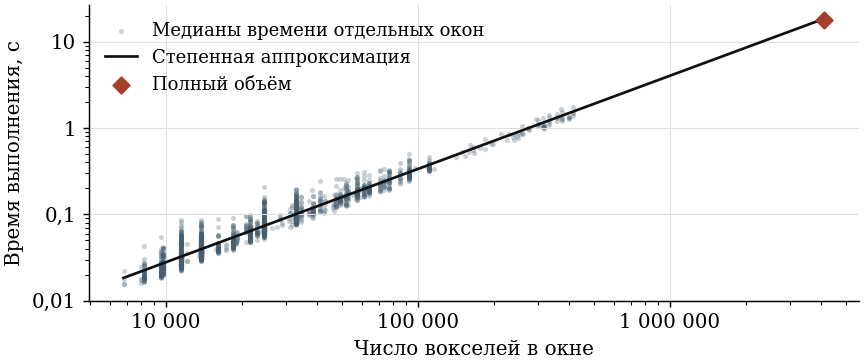

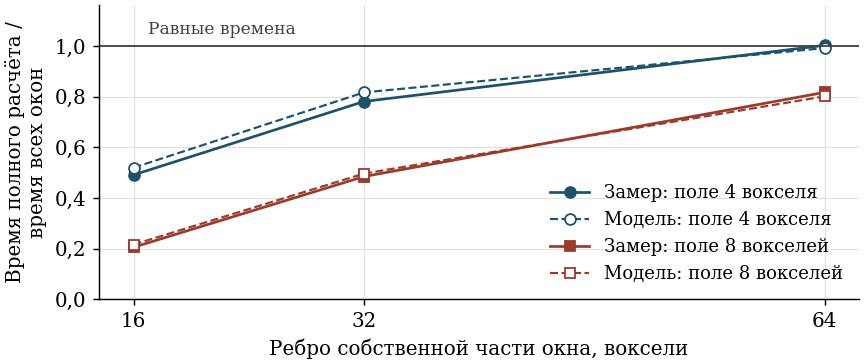

In [ ]:
plt.rcParams.update({'font.family':'DejaVu Serif','font.size':11,
                     'axes.spines.top':False,'axes.spines.right':False,
                     'pdf.fonttype':42,'svg.fonttype':'none'})
fig1,ax=plt.subplots(figsize=(6.65,2.8),constrained_layout=True)
ax.scatter(window_timings.voxels,window_timings.t_median_s,s=8,color='#465e70',alpha=.28,
           linewidths=0,rasterized=True,label='Медианы времени отдельных окон')
xx=np.geomspace(window_timings.voxels.min(),n,250)
ax.plot(xx,np.exp(log_c)*xx**alpha,color='#111111',lw=1.5,
        label='Степенная аппроксимация')
ax.scatter([n],[obs['calibration']['full_wall_median_s']],marker='D',s=42,
           color='#a5402d',zorder=4,label='Полный объём')
ax.set(xscale='log',yscale='log',xlabel='Число вокселей в окне',ylabel='Время выполнения, с')
ax.set_xticks([10000,100000,1000000],labels=['10 000','100 000','1 000 000'])
ax.set_yticks([0.01,0.1,1,10],labels=['0,01','0,1','1','10'])
ax.grid(True,which='major',color='.87',linewidth=.6)
ax.legend(fontsize=10,loc='upper left',frameon=False,handlelength=1.8)
fig2,ax=plt.subplots(figsize=(6.65,2.8),constrained_layout=True)
for margin,marker,color in [(4,'o','#1d526d'),(8,'s','#9a3b2c')]:
    g=table1[table1.margin==margin]
    unit='вокселя' if margin==4 else 'вокселей'
    ax.plot(g.core_side,g.measured_ratio,marker=marker,color=color,lw=1.5,
            label=f'Замер: поле {margin} {unit}')
    ax.plot(g.core_side,g.model_ratio,marker=marker,markerfacecolor='white',color=color,
            linestyle='--',lw=1.2,label=f'Модель: поле {margin} {unit}')
ax.axhline(1,color='.25',lw=1)
ax.text(17,1.03,'Равные времена',fontsize=9.5,color='.25',va='bottom')
ax.set(xlabel='Ребро собственной части окна, воксели',
       ylabel='Время полного расчёта /\nвремя всех окон',
       xticks=[16,32,64],ylim=(0,1.16))
ax.set_yticks([0,.2,.4,.6,.8,1],labels=['0,0','0,2','0,4','0,6','0,8','1,0'])
ax.grid(True,color='.88',linewidth=.6)
ax.legend(fontsize=10,loc='lower right',frameon=False,handlelength=2.2)
if SAVE_OUTPUTS:
    OUTPUT.mkdir(parents=True,exist_ok=True)
    for number,fig in enumerate([fig1,fig2],1):
        for ext in ['png','pdf']:
            fig.savefig(OUTPUT/f'figure_{number}.{ext}',dpi=600)
plt.show()